# Level 5 · Evals and tracing

**AI Engineer course · notebook 5 of 6 · theory edition: theory next to its examples**

An **eval** is a function from (input, output, reference) to a score with a comment. A **trace** is the record of what the
agent actually did. You cannot improve what you do not score, and you cannot debug what you did not trace.
This level builds no new agent: it measures one, in all three layers.

**After this notebook you can:**

1. Write an evaluator as a plain function, run it over a task set, and report the score with its n and its cost.
2. Use a model as a judge, and measure how often it is right (TPR, TNR) and whether the order of two answers decides
   its verdict.
3. Grade an agent by its trajectory (which tools, in which order) and by its outcome (the state of the world after the run).
4. Explain why 75 % on one run becomes about 42 % on three runs in a row (pass^k).
5. Trace an agent with OpenTelemetry and follow one trace id from the agent into the gateway's bill.
6. Run the same tasks and graders over three agents (A, B, C) and read the cost next to the score.

| Part | Topic | Needs |
|---|---|---|
| 0 | Setup: the data and the functions the parts use | – |
| 1 | The first evaluator, by hand | Part 0 |
| 2 | A model as the judge: calibration and bias | Part 1 |
| 3 | Trajectory evals: which tools, in which order | Part 1 |
| 4 | Outcome evals and pass^k | Parts 1 and 3 |
| 5 | Tracing: one trace id from the agent to the gateway | Parts 1 and 3 |
| 6 | The harness: three agents, one table | Parts 1, 3 and 5 |
| 7 | Recap | – (the clean-up cell needs Parts 4 and 5) |

Each part is one video chapter. Run Part 0 first; after that the parts can be run in any order unless the table says otherwise.

## How this edition is built

As in Level 2, all examples use one made-up company, **NovaBank**, and its customer support assistant, and "the
platform" means the OpenAI-compatible gateway your applications call at work; this notebook runs a toy copy of it.
Each part is a chain of short theory sections (T 1.1, T 1.2, …), each followed by the examples that show it. What an
earlier level already explained is not explained again: the text says where it is, e.g. "(Level 2, T
1.5)". 🔮 **Predict** marks a cell to guess before you run it, 💥 **Break it** an error caused on purpose. The three
layers are **A** the OpenAI API, **B** LangChain + LangGraph and **C** Agno.

The functions this notebook needs but does not teach live in `level_5_helpers.py`, next to this notebook; the first
cell imports each name it uses.

**Cost.** When we ran it, one full run of this notebook cost about 0.12 USD at October 2026 prices. The last cell prints
what your run cost.

---
# Part 0 · Setup<a id="p0"></a>

Part 0 loads the data and the functions the other parts use. Nothing in it is new: the toy gateway is the one of
Level 1, the agent loop the one of Level 2. Spans and call trees (Level 2, T 2.2) are built by hand in Part 5, where
the first tree appears ([T 5.4](#t5-4)).

### The data<a id="p0-data"></a>

| Name | What it is | Used in |
|---|---|---|
| `TICKETS` | 14 customer messages, each labelled by hand: `(message, category, priority)` (from `level_5_helpers.py`) | the `classify` tasks of `EVALSET` |
| `HANDBOOK` | a made-up product handbook: 12 products, six sentences each, the same text every run; no Platinum account, no Gold card (from `level_5_helpers.py`) | `search_handbook`, the `rag` and `abstain` tasks |
| `BANK` | two made-up accounts: A-1001 (four payments, the gym twice on the same day) and A-1002 (two payments, one a train ticket) | the four tools |
| `REFUNDS` | an empty list; every refund the agent makes lands here | `refund` |
| `SYSTEM` | the agent's system prompt: five rules, among them "Before any refund, look the transaction up with find_transactions." | `run_agent`; [Part 3](#ex3-6), [Part 5](#ex5-3); the safety rule of [T 3.4](#t3-4) |
| `RAG_QUESTIONS` | six handbook questions, each with its product and the regex that finds the answer in the product's section | `EVALSET`; [Part 2](#ex2-2) |
| `TOOL_TASKS` | eight requests that need tools, each with the tools a good agent calls | `EVALSET` |
| `ABSTAIN_QUESTIONS` | two questions about products the handbook does not have | `EVALSET`; [Part 2](#ex2-6) |
| `CLASSIFY` | the instruction in front of each ticket in a `classify` task | `EVALSET` |
| `EVALSET` | the eval set: 30 tasks, 14 `classify`, 6 `rag`, 8 `tools`, 2 `abstain`; one task explained in [T 1.2](#t1-2) | [Part 1](#ex1-1), [Part 3](#ex3-1), [Part 6](#ex6-2) |
| `EVALSET_VERSION` | `"evalset-v1"`, stored next to every result | [Part 1](#ex1-2) |

### The functions<a id="p0-functions"></a>

Imported from `level_5_helpers.py`, by section of the file:

| Name | What it does | Used in |
|---|---|---|
| **1. Models** | | |
| `SMALL`, `LARGE` | the real models behind the aliases `small` and `large`; [0.1](#p0-1) prints them | [Part 2](#ex2-4), [Part 6](#ex6-3) |
| **2. Printing** | | |
| `show_messages(messages, title)` | prints a conversation, one message per block, every text whole | [Part 3](#ex3-1), [Part 4](#ex4-2) |
| `show_json(title, value)` | prints one object as indented JSON, whole, under a title | [0.4](#p0-4), [Part 3](#ex3-1) |
| `bar_chart(values, title)` | draws a horizontal bar chart | [Part 6](#ex6-2) |
| **3. Small tools** | | |
| `count_tokens(text)` | the number of tokens of a text | [0.3](#p0-3) |
| `run_many(function, items)` | calls `function` on every item, eight at a time; the results in the order of the items | [Part 2](#ex2-3), [Part 3](#ex3-4), [Part 5](#ex5-5), [Part 6](#ex6-1) |
| `pass_rate(scores)` | writes 0/1 scores as `k/n = rate`; a missing score (`None`) is left out | [Part 1](#ex1-3), [Part 4](#ex4-3), [Part 6](#ex6-2) |
| **4. The toy gateway** | | |
| `gateway_app`, `serve(app, port)`, `UPSTREAM` | the gateway as a web app; starts it in a background thread; the provider's address | [0.2](#p0-2) |
| `ask(client, prompt)` | sends one question, returns the answer's text | [Part 2](#ex2-6), [Part 4](#ex4-3), [Part 5](#ex5-1) |
| `gateway_log` | one entry per request: the app, the real model, tokens, cost, seconds, the whole body sent ([T 1.3](#t1-3)) | [Part 1](#ex1-2) to Part 7 |
| `before_call` | the hooks the gateway runs on every request | [Part 5](#ex5-1) |
| `ALIASES` | maps an alias to a real model: `small` → `gpt-4.1-mini` | [Part 6](#ex6-3) |
| `show_sent(app)` | prints the last request body one app sent, whole | [Part 2](#ex2-11), [Part 3](#ex3-9) |
| `stop_servers()`, `spent()` | stops every server `serve` started; the USD the gateway billed so far | Part 7, Clean up |
| **5. NovaBank data** | | |
| `section(product)` | the handbook text of one product: the six sentences under its heading | `EVALSET`; [Part 2](#ex2-2) |
| **6. Call trees** | | |
| `spans_of(exporter, trace_id)`, `show_trace(exporter, trace_id, title)` | the spans of one trace; print them as a call tree ([T 5.4](#t5-4)) | [Part 5](#ex5-3), [Part 6](#ex6-5) |
| **7. Measuring** | | |
| `sent_summary(app)` | the calls, tokens and the shape of the last request of one app, from the gateway log | [Part 3](#ex3-9) |

Defined in Part 0 itself:

| Name | What it does | Used in |
|---|---|---|
| the toy gateway, `GATEWAY_URL`, `TEAM_KEY` | the gateway of this notebook on port 5150, its address, the support team's key | every request; Layers B and C in [Part 2](#ex2-9) and [Part 3](#ex3-6) |
| `client` | Layer A's OpenAI client of the gateway | `run_agent`; [Part 2](#ex2-1), [Part 4](#ex4-3), [Part 5](#ex5-1) |
| `get_balance`, `find_transactions`, `refund`, `search_handbook` | the four tools: the balance of an account; its payments, filtered by merchant; a refund (it trusts its caller and appends to `REFUNDS`); the handbook section that matches a query best | `TOOLS`; [Part 3](#ex3-2), [Part 5](#ex5-3) |
| `TOOLS` | the four tools, in a list | `run_agent`; [Part 3](#ex3-6), [Part 5](#ex5-3) |
| `tool_schema(function)` | the tool description the API needs, from the function's name, docstring and typed arguments | `run_agent`; [Part 3](#ex3-6), [Part 5](#ex5-3) |
| `call_tool(call, tools)` | runs one tool call; an exception becomes the text `"Error: …"` for the model | `run_agent`; [Part 5](#ex5-2) |
| `run_agent(question, tools, system, model, headers, max_steps)` | the agent loop of Level 2; returns `{"answer", "messages"}` ([T 1.2](#t1-2)) | [Part 1](#ex1-3), [Part 3](#ex3-1), [Part 4](#ex4-2) |
| `STARTED` | the time the run started | Part 7, Clean up |

### 0.1 · Imports<a id="p0-1"></a>

In [1]:
import inspect
import json
import math
import os
import random
import re
import time
from collections import Counter

import pandas as pd
from IPython.display import display
from openai import OpenAI

from level_5_helpers import (
    # 1. models
    SMALL, LARGE,
    # 2. printing
    show_json, show_messages, bar_chart,
    # 3. small tools
    count_tokens, run_many, pass_rate,
    # 4. the toy gateway
    UPSTREAM, gateway_app, serve, stop_servers, ask, gateway_log, before_call, ALIASES, show_sent, spent,
    # 5. NovaBank data
    TICKETS, HANDBOOK, section,
    # 6. call trees
    spans_of, show_trace,
    # 7. measuring helpers
    sent_summary,
)

STARTED = time.time()                                               # the last cell prints how long the run took
print("Models of this level: SMALL =", SMALL, "| LARGE =", LARGE)

Models of this level: SMALL = gpt-4.1-mini | LARGE = gpt-6.1-sol


### 0.2 · The toy gateway and its client<a id="p0-2"></a>

In [2]:
GATEWAY_URL = serve(gateway_app, port=5150)                         # 5150: the toy gateway of this notebook
TEAM_KEY = "sk-team-support"
# Layer A's client of the toy gateway on 5150, with the support team's key.
client = OpenAI(base_url=GATEWAY_URL, api_key=TEAM_KEY, timeout=180, max_retries=5)
print("gateway at", GATEWAY_URL, "→ provider at", UPSTREAM)

gateway at http://127.0.0.1:5150/v1 → provider at https://api.openai.com/v1/


### 0.3 · The tickets and the handbook<a id="p0-3"></a>

In [3]:
print(f"=== The {len(TICKETS)} tickets ===")
pd.DataFrame(TICKETS, columns=["message", "category", "priority"])

=== The 14 tickets ===


,message,category,priority
0,There are two payments on my card that I did not make.,CARD,P1
1,The cash machine kept my card and I cannot get it back.,CARD,P2
2,How do I change the PIN of my card?,CARD,P3
3,Contactless payments stopped working on my card.,CARD,P2
4,I sent 900 EUR to the wrong account number by mistake.,TRANSFER,P1
5,My standing order for the rent did not go out this month.,TRANSFER,P2
6,How long does a transfer to the US take?,TRANSFER,P3
7,I am locked out of online banking after three wrong passwords.,ACCOUNT,P2
8,I moved. How do I update my address?,ACCOUNT,P3
9,Can I open a second savings account?,ACCOUNT,P3


In [4]:
print(f"Handbook size: {count_tokens(HANDBOOK):,} tokens")
print("\n=== The whole handbook: its title and the 12 products ===")
print(HANDBOOK)

Handbook size: 2,137 tokens

=== The whole handbook: its title and the 12 products ===
NovaBank product handbook, edition 2026-10.

## Student account
The Student account costs 5 EUR per month. The daily ATM withdrawal limit is 450 EUR and the daily transfer limit is 25000 EUR.
The interest rate is 0.5% per year. A replacement card costs 0 EUR and arrives within 7 working days.
Customers can open the Student account in the app or in a branch with a valid id. Closing it is free after 6 months.
Support for the Student account is available by phone from 8:00 to 22:00 on working days, and by chat at any time.
Payments abroad with the Student account cost 0% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.
Disputes about Student account transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 5 working days.

## Everyday account
The Everyday account costs 9 EUR per month. The daily ATM withdrawal limit is 1000 EUR and the dail

### 0.4 · The bank and its four tools<a id="p0-4"></a>

In [5]:
BANK = {  # two made-up accounts
    "A-1001": {"balance": 1250.40, "transactions": [
        {"id": "T-5001", "date": "2026-10-01", "text": "Coffee Corner", "amount": 4.20},
        {"id": "T-5002", "date": "2026-10-03", "text": "City Gym membership", "amount": 39.00},
        {"id": "T-5003", "date": "2026-10-03", "text": "City Gym membership", "amount": 39.00},
        {"id": "T-5004", "date": "2026-10-05", "text": "Online shop order", "amount": 120.00}]},
    "A-1002": {"balance": 87.15, "transactions": [
        {"id": "T-6001", "date": "2026-10-02", "text": "Train ticket", "amount": 23.50},
        {"id": "T-6002", "date": "2026-10-04", "text": "Supermarket", "amount": 56.80}]},
}
REFUNDS = []  # every refund the agent makes lands here


def get_balance(account_id: str) -> str:
    """Current balance of a NovaBank account, for example A-1001."""
    account = BANK.get(account_id)
    return f"{account_id}: {account['balance']:.2f} EUR" if account else f"No account {account_id}."


def find_transactions(account_id: str, text: str = "") -> str:
    """Recent transactions of an account. Optional: only those whose description contains `text`, e.g. 'gym'."""
    account = BANK.get(account_id)
    if not account:
        return f"No account {account_id}."
    return json.dumps([t for t in account["transactions"] if text.lower() in t["text"].lower()])


def refund(transaction_id: str, amount: float) -> str:
    """Refund an amount of one transaction to the customer. Look the transaction up with find_transactions first."""
    REFUNDS.append({"transaction_id": transaction_id, "amount": amount})
    return f"Refund of {amount:.2f} EUR for {transaction_id} registered."


def search_handbook(query: str) -> str:
    """Search the NovaBank product handbook. Returns the product section that matches the query best."""
    words = set(re.findall(r"\w+", query.lower()))
    sections = HANDBOOK.split("\n## ")[1:]
    overlap = [len(words & set(re.findall(r"\w+", section.lower()))) for section in sections]
    return "## " + sections[overlap.index(max(overlap))]


show_json("The bank: both accounts with all their payments", BANK)

=== The bank: both accounts with all their payments ===
{
  "A-1001": {
    "balance": 1250.4,
    "transactions": [
      {
        "id": "T-5001",
        "date": "2026-10-01",
        "text": "Coffee Corner",
        "amount": 4.2
      },
      {
        "id": "T-5002",
        "date": "2026-10-03",
        "text": "City Gym membership",
        "amount": 39.0
      },
      {
        "id": "T-5003",
        "date": "2026-10-03",
        "text": "City Gym membership",
        "amount": 39.0
      },
      {
        "id": "T-5004",
        "date": "2026-10-05",
        "text": "Online shop order",
        "amount": 120.0
      }
    ]
  },
  "A-1002": {
    "balance": 87.15,
    "transactions": [
      {
        "id": "T-6001",
        "date": "2026-10-02",
        "text": "Train ticket",
        "amount": 23.5
      },
      {
        "id": "T-6002",
        "date": "2026-10-04",
        "text": "Supermarket",
        "amount": 56.8
      }
    ]
  }
}


In [6]:
JSON_TYPES = {str: "string", int: "integer", float: "number", bool: "boolean"}


def tool_schema(function):
    """The tool description the API needs, read from a plain Python function."""
    parameters = inspect.signature(function).parameters
    properties = {name: {"type": JSON_TYPES[p.annotation]} for name, p in parameters.items()}
    required = [name for name, p in parameters.items() if p.default is inspect.Parameter.empty]
    return {"type": "function", "function": {"name": function.__name__, "description": function.__doc__,
            "parameters": {"type": "object", "properties": properties, "required": required}}}


def call_tool(call, tools):
    """Run one tool call. A bad call goes back to the model as an error text instead of crashing the loop."""
    try:
        function = {f.__name__: f for f in tools}[call.function.name]
        return str(function(**json.loads(call.function.arguments)))
    except Exception as error:
        return f"Error: {error}"


TOOLS = [get_balance, find_transactions, refund, search_handbook]

### 0.5 · The agent<a id="p0-5"></a>

In [7]:
SYSTEM = ("You are the NovaBank support assistant. Use the tools to look things up; never guess a number. "
          "Answer in one or two sentences. If the handbook does not answer the question, say \"I don't know\". "
          "Before any refund, look the transaction up with find_transactions. Refund double charges without asking.")


def run_agent(question, tools=TOOLS, system=SYSTEM, model="small", headers=None, max_steps=6):
    """The Level 2 loop: ask the model, run the tools it asks for, repeat until it answers in text."""
    messages = [{"role": "system", "content": system}, {"role": "user", "content": question}]
    schemas = [tool_schema(f) for f in tools]
    for step in range(max_steps):
        response = client.chat.completions.create(model=model, messages=messages, tools=schemas, extra_headers=headers)
        message = response.choices[0].message
        messages.append(message.model_dump(include={"role", "content", "tool_calls"}, exclude_none=True))
        if not message.tool_calls:
            return {"answer": message.content or "", "messages": messages}
        for call in message.tool_calls:
            messages.append({"role": "tool", "tool_call_id": call.id, "content": call_tool(call, tools)})
    return {"answer": "(no answer after max_steps)", "messages": messages}

### 0.6 · The eval set<a id="p0-6"></a>

In [8]:
RAG_QUESTIONS = [  # (question, product, where the answer stands in its handbook section, unit)
    ("What is the daily transfer limit of the Student account?", "Student account", r"daily transfer limit is (\d+) EUR", "EUR"),
    ("What is the daily ATM withdrawal limit of the Travel card?", "Travel card", r"ATM withdrawal limit is (\d+) EUR", "EUR"),
    ("How much does the Fixed deposit cost per month?", "Fixed deposit", r"costs (\d+) EUR per month", "EUR"),
    ("What is the yearly interest rate of the Business account?", "Business account", r"interest rate is ([\d.]+)%", "%"),
    ("How much does a replacement card cost for the Youth account?", "Youth account", r"replacement card costs (\d+) EUR", "EUR"),
    ("Within how many days must I report a dispute about a Credit card transaction?", "Credit card", r"within (\d+) days", "days"),
]
TOOL_TASKS = [  # (request, the tools a good agent calls)
    ("What is the balance of account A-1001?", ["get_balance"]),
    ("Show me the gym payments on account A-1001.", ["find_transactions"]),
    ("I was charged twice for the gym on account A-1001. Please refund the second charge.", ["find_transactions", "refund"]),
    ("Refund transaction T-6001 on account A-1002 in full, the train was cancelled.", ["find_transactions", "refund"]),
    ("How much money is on A-1002, and what does the Travel card cost per month?", ["get_balance", "search_handbook"]),
    ("Did I pay anything at Coffee Corner on account A-1001?", ["find_transactions"]),
    ("What is the daily ATM withdrawal limit of the Premium account?", ["search_handbook"]),
    ("Please refund the online shop order on A-1001, the parcel never arrived.", ["find_transactions", "refund"]),
]
ABSTAIN_QUESTIONS = ["What is the monthly fee of the Platinum account?", "What is the daily ATM withdrawal limit of the Gold card?"]
EVALSET_VERSION = "evalset-v1"  # change it whenever a task or a reference changes, and store it next to every result
CLASSIFY = "Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: "

EVALSET = []
for i, (text, category, priority) in enumerate(TICKETS, start=1):
    EVALSET.append({"id": f"c{i:02d}", "kind": "classify", "input": CLASSIFY + text, "reference": category, "expected_tools": []})
for i, (question, product, pattern, unit) in enumerate(RAG_QUESTIONS, start=1):
    reference = re.search(pattern, section(product)).group(1)  # the reference is read from the handbook, never typed
    EVALSET.append({"id": f"r{i}", "kind": "rag", "input": question, "reference": reference, "expected_tools": ["search_handbook"]})
for i, (request, tools) in enumerate(TOOL_TASKS, start=1):
    EVALSET.append({"id": f"t{i}", "kind": "tools", "input": request, "reference": None, "expected_tools": tools})
for i, question in enumerate(ABSTAIN_QUESTIONS, start=1):
    EVALSET.append({"id": f"a{i}", "kind": "abstain", "input": question, "reference": "I don't know", "expected_tools": ["search_handbook"]})

print("Eval set:", EVALSET_VERSION, "·", len(EVALSET), "tasks ·", dict(Counter(task["kind"] for task in EVALSET)))
# Tool tasks have no reference answer (NaN): Part 3 grades them by the tools they call.
print(f"\n=== The eval set: all {len(EVALSET)} tasks ===")
pd.DataFrame(EVALSET)

Eval set: evalset-v1 · 30 tasks · {'classify': 14, 'rag': 6, 'tools': 8, 'abstain': 2}

=== The eval set: all 30 tasks ===


,id,kind,input,reference,expected_tools
0,c01,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: There are two payments on my card that I did not make.",CARD,[]
1,c02,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: The cash machine kept my card and I cannot get it back.",CARD,[]
2,c03,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: How do I change the PIN of my card?",CARD,[]
3,c04,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: Contactless payments stopped working on my card.",CARD,[]
4,c05,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: I sent 900 EUR to the wrong account number by mistake.",TRANSFER,[]
5,c06,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: My standing order for the rent did not go out this month.",TRANSFER,[]
6,c07,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: How long does a transfer to the US take?",TRANSFER,[]
7,c08,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: I am locked out of online banking after three wrong passwords.",ACCOUNT,[]
8,c09,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: I moved. How do I update my address?",ACCOUNT,[]
9,c10,classify,"Which category fits this customer message: CARD, TRANSFER, ACCOUNT or LOAN? Reply with the category only.\n\nMessage: Can I open a second savings account?",ACCOUNT,[]


---
# Part 1 · The first evaluator, by hand<a id="p1"></a>

"It looks good" is not a measurement. Before you change a prompt, swap the model behind an alias or ship a new tool, you
need a number you can compare, and that number comes from an **evaluator**: a plain function that looks at one input, one
output and (if there is one) the reference answer, and returns a score with a comment. This part writes three of them in
plain code and reports the agent's score with its n and its cost.

### T 1.1 · What, how and when: the three questions of every eval<a id="t1-1"></a>

Three questions decide every eval:

| Question | Answers |
|---|---|
| **What** do you grade? | the final answer, the steps the agent took (trajectory), the state of the world after the run (outcome) |
| **How** do you grade? | code (exact, cheap, deterministic), a model (Part 2), a human (the ground truth for both) |
| **When** do you run it? | before you change a prompt, when the model behind an alias changes, every night in CI |

The answers to the first two give four kinds of grader. This notebook builds one part around each:

![Four kinds of grader: code on the answer, a model as judge, the trajectory, the outcome](img/l5_graders.svg)

| Grader | Looks at | Decides with | Part |
|---|---|---|---|
| code | the answer text | a rule in Python: the same input, the same score, for free | 1 |
| a model as judge | the answer text, with the question and the reference | a second model call, which costs money and can be wrong | 2 |
| trajectory | the tool calls of the run | a comparison with the expected calls | 3 |
| outcome | the world after the run: a table, a refund | a query of the world | 4 |

Start small: 20 to 50 tasks, pass/fail scores (not 1 to 10), and a code grader wherever code can decide. A pass/fail
score needs one clear line between good and bad; a scale of 1 to 10 needs ten of them, and two graders, or the same
judge twice, rarely agree on 6 against 7.

### T 1.2 · An evaluator is a function<a id="t1-2"></a>

One shape for every grader in this notebook: `grader(task, output)` returns `{"score": 0.0 or 1.0, "comment": "..."}`.

![One eval: a task of the eval set goes to the system under test; its output and the task go to the grader; the grader writes one row of the report](img/l5_eval_anatomy.svg)

| Argument | What it is |
|---|---|
| `task` | one record of the eval set `EVALSET` ([Part 0](#p0-data)): `id`, `kind`, `input`, `reference`, `expected_tools` |
| `output` | what the system under test returned for `task["input"]`: the dict of `run_agent`, with `answer` (the text of the last reply: what the customer reads) and `messages` (the whole conversation: system prompt, question, every reply and every tool result) |

**One task of the eval set** is one row of the table that [0.6](#p0-6) prints: an `id` that never changes (every result
is stored with it); the `kind`, which decides the grader (`classify`: 14 tickets, `rag`: 6 handbook questions, `tools`: 8
requests that need tools, `abstain`: 2 questions the handbook cannot answer); the `input` the system under test gets;
the `reference`, the answer we expect, as text (`None` for a tool task, which pandas prints as `NaN`); and the
`expected_tools`, which Part 3 compares the run with.

What a grader returns is a dict of two keys: the `score`, and a `comment` that says why. [Example 1.1](#ex1-1) prints two
results.

The comment is not decoration. When a score drops, the comments of the failing rows are the first thing you read; without
them you would have to run the agent again to find out what went wrong.

**The first grader**, `exact_category`, grades the `classify` tasks. It normalises the answer a little (spaces and a
final full stop off, upper case) and compares it with the reference using `==`. Normalise only what does not change the
meaning: `"card."` and `"CARD"` say the same, but "This is about a card." is not what the instruction asked for, the
category only.

### Example 1.1 · An evaluator is a function<a id="ex1-1"></a>

In [9]:
def exact_category(task, output):
    """Code grader: the answer is exactly the expected category."""
    answer = output["answer"].strip().strip(".").upper()
    return {"score": float(answer == task["reference"]), "comment": f"expected {task['reference']}, got {answer!r}"}


def tasks_of(kind):
    """All tasks of one kind from the eval set."""
    return [task for task in EVALSET if task["kind"] == kind]


print("=== exact_category on two answers to ticket c01 ===")
print(exact_category(tasks_of("classify")[0], {"answer": "CARD."}))
print(exact_category(tasks_of("classify")[0], {"answer": "This is about a card."}))

=== exact_category on two answers to ticket c01 ===
{'score': 1.0, 'comment': "expected CARD, got 'CARD'"}
{'score': 0.0, 'comment': "expected CARD, got 'THIS IS ABOUT A CARD'"}


### T 1.3 · The run and the report: k/n, cost, time<a id="t1-3"></a>

`run_eval(agent, tasks, evaluators)` runs the agent on each task, scores the output with the graders for that task's kind
(`evaluators` maps a kind to a list of graders), and puts the **cost next to the score**. For each task it:

1. remembers where the gateway log ends, and the time;
2. runs the agent on `task["input"]`;
3. takes the log entries written since step 1 as the task's bill, and the time since step 1 as its seconds;
4. runs every grader of the task's kind, and writes one row per grader.

The gateway log is the toy gateway's of Level 1 (section 3.4): one entry per request, with its cost.

Step 3 works only because the tasks run one after another: no other request can land in the log between steps 1 and 3.
Part 6 runs eight at a time, and then the trace id of Part 5 keeps the bill right ([T 5.2](#t5-2)).

Each row of the result holds the task, the grader, its score and comment, the agent's whole answer, the seconds, the cost
and the version of the eval set; [Example 1.2](#ex1-2) prints the first rows.

**The report** groups the rows by kind of task: the pass rate as `k/n` (`pass_rate`: the n always stands next to the
rate, and a missing score, `None`, is left out, not counted as a fail), the cost, the seconds per task
and the version. It is the report format for the rest of the notebook.

**How big must n be?** On 14 tasks one task moves the rate by 7 points. Two prompts that score 12/14 and 10/14 are only
two tickets apart, and two tickets can flip from one run to the next: on this little data the two cannot be told apart.
More tasks make each one count less. Start with 20 to 50; use more when you compare two versions.

### Example 1.2 · Run, score, and put the cost next to it<a id="ex1-2"></a>

In [10]:
def run_eval(agent, tasks, evaluators):
    """Run the agent on every task and score each output. evaluators: {kind: [grader, ...]}."""
    rows = []
    for task in tasks:
        first, started = len(gateway_log), time.perf_counter()
        output = agent(task["input"])
        seconds, cost = round(time.perf_counter() - started, 1), sum(entry["cost"] for entry in gateway_log[first:])
        for evaluator in evaluators[task["kind"]]:
            result = evaluator(task, output)
            rows.append({"id": task["id"], "kind": task["kind"], "evaluator": evaluator.__name__, "score": result["score"],
                         "comment": result["comment"], "answer": output["answer"], "seconds": seconds, "cost": cost,
                         "version": EVALSET_VERSION})
    return pd.DataFrame(rows)


# Try it on two tickets with a stand-in agent that always answers "CARD". No model is called, so the cost is 0.
print("=== run_eval: a stand-in agent that always answers CARD, on tickets c04 and c05 ===")
run_eval(lambda text: {"answer": "CARD"}, tasks_of("classify")[3:5], {"classify": [exact_category]})

=== run_eval: a stand-in agent that always answers CARD, on tickets c04 and c05 ===


,id,kind,evaluator,score,comment,answer,seconds,cost,version
0,c04,classify,exact_category,1.0,"expected CARD, got 'CARD'",CARD,0.0,0,evalset-v1
1,c05,classify,exact_category,0.0,"expected TRANSFER, got 'CARD'",CARD,0.0,0,evalset-v1


Row 1 fails: ticket c05 is a `TRANSFER`, and the stand-in always says `CARD`.

### Example 1.3 · 🔮 Fourteen tickets, one number<a id="ex1-3"></a>

🔮 **Predict.** How many of the 14 tickets will the agent get right? And if it gets 12, is it a better agent than one
that gets 10?

In [11]:
classify = run_eval(run_agent, tasks_of("classify"), {"classify": [exact_category]})
print("=== The agent on the 14 tickets: every row of run_eval ===")
display(classify)
print("accuracy:", pass_rate(classify["score"]), "· cost:", round(classify["cost"].sum(), 5), "USD ·",
      round(classify["seconds"].sum()), "s")
for row in classify[classify["score"] < 1].itertuples():
    print("  wrong:", row.id, row.comment)

=== The agent on the 14 tickets: every row of run_eval ===


,id,kind,evaluator,score,comment,answer,seconds,cost,version
0,c01,classify,exact_category,1.0,"expected CARD, got 'CARD'",CARD,0.7,0.000108,evalset-v1
1,c02,classify,exact_category,1.0,"expected CARD, got 'CARD'",CARD,0.4,0.000108,evalset-v1
2,c03,classify,exact_category,1.0,"expected CARD, got 'CARD'",CARD,0.4,0.000107,evalset-v1
3,c04,classify,exact_category,1.0,"expected CARD, got 'CARD'",CARD,0.5,0.000106,evalset-v1
4,c05,classify,exact_category,1.0,"expected TRANSFER, got 'TRANSFER'",TRANSFER,0.5,0.000108,evalset-v1
5,c06,classify,exact_category,1.0,"expected TRANSFER, got 'TRANSFER'",TRANSFER,0.5,0.000108,evalset-v1
6,c07,classify,exact_category,1.0,"expected TRANSFER, got 'TRANSFER'",TRANSFER,0.4,0.000107,evalset-v1
7,c08,classify,exact_category,1.0,"expected ACCOUNT, got 'ACCOUNT'",ACCOUNT,0.5,0.000108,evalset-v1
8,c09,classify,exact_category,1.0,"expected ACCOUNT, got 'ACCOUNT'",ACCOUNT,0.4,0.000107,evalset-v1
9,c10,classify,exact_category,1.0,"expected ACCOUNT, got 'ACCOUNT'",ACCOUNT,0.4,0.000106,evalset-v1


accuracy: 14/14 = 100% · cost: 0.00151 USD · 7 s


When we ran it, the agent got all 14 right. The honest sentence is "the agent was right on 14 of 14 tickets", not "the
agent is 100 % right": on 14 tasks one ticket moves the score by 7 points, so 12/14 and 10/14 cannot be told apart
([T 1.3](#t1-3), *How big must n be?*).

### T 1.4 · Graders have bugs<a id="t1-4"></a>

A grader is code, and code has bugs. The obvious grader for a number reference is "the reference text appears in the
answer": `task["reference"] in answer`. It can be wrong in both directions:

| Kind of mistake | When it happens | Effect on the score |
|---|---|---|
| **false fail**: a right answer fails | the answer writes the same number in another format: a thousands separator, trailing zeros | the agent looks worse than it is |
| **false pass**: a wrong answer passes | the reference is a part of another number in the answer | the agent looks better than it is |

A grader bug looks exactly like an agent bug in the final number: "4/6" says nothing about whether the agent or the grader
failed. So a grader is tested like any other code, before its number is trusted:

1. Write a few answers by hand, each with the verdict a person gives it: right or wrong.
2. Include the tricky formats: separators, decimals, a number that contains the reference.
3. Run the grader on them. Every disagreement with the person is a grader bug.

Part 2 does the same for a model as judge, on more cases, and puts numbers on its mistakes ([T 2.2](#t2-2)).

### T 1.5 · Code graders for numbers and for "I don't know"<a id="t1-5"></a>

**Numbers.** The `rag` references are numbers, written as text: `"25000"`, `"3.9"`. They are not typed by hand: Part 0
reads each one from its product's handbook section with a regex, so they cannot drift from the text. An answer may
write the same number in many ways: `25,000`, `25000`, `EUR 25000.00`. So the grader compares numbers, not strings.
`numbers_in(text)` finds every number in a text with the regex `\d[\d,]*(?:\.\d+)?` (a digit, then digits and commas,
then maybe a decimal part), drops the commas and turns each into a float:

| Text | `numbers_in(text)` |
|---|---|
| `"You can transfer up to 25,000 EUR a day."` | `[25000.0]` |
| `"The limit is EUR 450.00."` | `[450.0]` |
| `"The rate is 3.90% per year."` | `[3.9]` |
| `"It costs 150 EUR per month."` | `[150.0]` |

`answer_contains_reference(task, output)` passes when `float(task["reference"])` is one of the numbers of the answer. Its
comment lists them all, for example `"expected 10, found [10.0, 7.0]"`. It has a blind spot: an answer that lists every
limit of the handbook contains the right one too, and passes.

**"I don't know".** The two `abstain` tasks ask about products the handbook does not have. A good answer says so and
names no amount; an invented fee is the worst possible answer. `abstains(task, output)` is plain code again: it passes
when the answer contains one of the markers and no number at all.

| Marker in `ABSTAIN_MARKERS` |
|---|
| `i don't know` · `i do not know` · `couldn't find` · `could not find` · `not in the handbook` · `no information` |

A model says "I don't know" in many ways, so the grader knows several, and is tested on each kind. It lowers the case
first and turns the typographic apostrophe `’` into `'`, so "I don’t know" counts too. "I don't know, but it is probably
9 EUR" fails: it has a number.

### Example 1.4 · 💥 Break it: a grader with a bug<a id="ex1-4"></a>

Here are five answers we graded by eye. 🔮 How many does the obvious grader get wrong?

In [12]:
CASES = [  # (reference, answer, is the answer right?)
    ("450", "The limit is 450 EUR.", True),
    ("450", "The limit is EUR 450.00.", True),
    ("25000", "You can transfer up to 25,000 EUR a day.", True),
    ("15", "It costs 150 EUR per month.", False),
    ("3.9", "The rate is 3.90% per year.", True),
]

print("=== The naive grader on five answers graded by eye ===")
for reference, answer, right in CASES:
    print(f"{answer:<44} right: {right!s:<5}  naive grader: {reference in answer}")

=== The naive grader on five answers graded by eye ===
The limit is 450 EUR.                        right: True   naive grader: True
The limit is EUR 450.00.                     right: True   naive grader: True
You can transfer up to 25,000 EUR a day.     right: True   naive grader: False
It costs 150 EUR per month.                  right: False  naive grader: True
The rate is 3.90% per year.                  right: True   naive grader: True


Two of five are wrong, in both directions: "25,000" fails a correct answer, and "150" passes a wrong one because "15" is
inside it, the two mistakes of [T 1.4](#t1-4). The fix of [T 1.5](#t1-5): compare numbers, not strings, then test the
grader on the same hand-made cases.

In [13]:
def numbers_in(text):
    """All numbers in a text, as floats: '25,000' → 25000.0, 'EUR 450.00' → 450.0."""
    return [float(number.replace(",", "")) for number in re.findall(r"\d[\d,]*(?:\.\d+)?", text)]


def answer_contains_reference(task, output):
    """Code grader for RAG: the reference number appears in the answer, in any format."""
    found = numbers_in(output["answer"])
    return {"score": float(float(task["reference"]) in found), "comment": f"expected {task['reference']}, found {found}"}


print("=== The fixed grader on the same five answers ===")
for reference, answer, right in CASES:
    score = answer_contains_reference({"reference": reference}, {"answer": answer})["score"]
    print(f"{answer:<44} right: {right!s:<5}  fixed grader: {score == 1.0}")

=== The fixed grader on the same five answers ===
The limit is 450 EUR.                        right: True   fixed grader: True
The limit is EUR 450.00.                     right: True   fixed grader: True
You can transfer up to 25,000 EUR a day.     right: True   fixed grader: True
It costs 150 EUR per month.                  right: False  fixed grader: False
The rate is 3.90% per year.                  right: True   fixed grader: True


### Example 1.5 · A grader for "I don't know"<a id="ex1-5"></a>

In [14]:
ABSTAIN_MARKERS = ("i don't know", "i do not know", "couldn't find", "could not find", "not in the handbook", "no information")


def abstains(task, output):
    """Code grader for unanswerable questions: says it does not know, and states no number."""
    answer = output["answer"].lower().replace("’", "'")
    said_so = any(marker in answer for marker in ABSTAIN_MARKERS)
    return {"score": float(said_so and not numbers_in(answer)), "comment": f"abstains: {said_so}, numbers: {numbers_in(answer)}"}


print("=== abstains on three answers: I don't know · I couldn't find · a fee of 9 EUR ===")
print(abstains({}, {"answer": "I don't know, the handbook has no Platinum account."}))
print(abstains({}, {"answer": "I couldn't find the Platinum account in the handbook."}))
print(abstains({}, {"answer": "The Platinum account costs 9 EUR per month."}))

=== abstains on three answers: I don't know · I couldn't find · a fee of 9 EUR ===
{'score': 1.0, 'comment': 'abstains: True, numbers: []'}
{'score': 1.0, 'comment': 'abstains: True, numbers: []'}
{'score': 0.0, 'comment': 'abstains: False, numbers: [9.0]'}


### Example 1.6 · One report for three kinds of task<a id="ex1-6"></a>

Now the agent on the six RAG questions and the two unanswerable ones, each with its grader. The second table is the
report of [T 1.3](#t1-3).

In [15]:
EVALUATORS = {"classify": [exact_category], "rag": [answer_contains_reference], "abstain": [abstains]}
part1 = run_eval(run_agent, tasks_of("rag") + tasks_of("abstain"), EVALUATORS)
print("=== The agent on the RAG and abstain tasks: every row of run_eval ===")
display(part1)
results = pd.concat([classify, part1])
by_kind = results.groupby("kind")
print("\n=== Report per kind of task: pass rate, cost, time ===")
pd.DataFrame({"pass rate": by_kind["score"].apply(pass_rate), "cost USD": by_kind["cost"].sum().round(5),
              "seconds per task": by_kind["seconds"].mean().round(1), "version": by_kind["version"].first()})

=== The agent on the RAG and abstain tasks: every row of run_eval ===


,id,kind,evaluator,score,comment,answer,seconds,cost,version
0,r1,rag,answer_contains_reference,1.0,"expected 25000, found [25000.0]","The daily transfer limit of the Student account is 25,000 EUR.",1.1,0.000326,evalset-v1
1,r2,rag,answer_contains_reference,1.0,"expected 2000, found [2000.0]",The daily ATM withdrawal limit of the Travel card is 2000 EUR.,1.1,0.000329,evalset-v1
2,r3,rag,answer_contains_reference,1.0,"expected 15, found [15.0]",The Fixed deposit costs 15 EUR per month.,1.3,0.000318,evalset-v1
3,r4,rag,answer_contains_reference,1.0,"expected 3.9, found [3.9]",The yearly interest rate of the Business account is 3.9%.,1.2,0.000325,evalset-v1
4,r5,rag,answer_contains_reference,1.0,"expected 10, found [10.0, 7.0]",A replacement card for the Youth account costs 10 EUR and arrives within 7 working days.,1.3,0.000334,evalset-v1
5,r6,rag,answer_contains_reference,1.0,"expected 90, found [90.0]",You must report a dispute about a Credit card transaction within 90 days.,1.5,0.000330,evalset-v1
6,a1,abstain,abstains,1.0,"abstains: True, numbers: []",The information about the monthly fee for the Platinum account is not found in the handbook excerpt I checked. I don't know the monthly fee of the Platinum account.,1.3,0.000351,evalset-v1
7,a2,abstain,abstains,1.0,"abstains: True, numbers: []",I couldn't find the daily ATM withdrawal limit information for the Gold card in the handbook. Would you like me to assist you with anything else?,1.3,0.000350,evalset-v1



=== Report per kind of task: pass rate, cost, time ===


,pass rate,cost USD,seconds per task,version
kind,,,,
abstain,2/2 = 100%,0.00070,1.3,evalset-v1
classify,14/14 = 100%,0.00151,0.5,evalset-v1
rag,6/6 = 100%,0.00196,1.2,evalset-v1


### 📌 Takeaways

- An evaluator is a plain function: `(task, output) → {"score", "comment"}`. Use code wherever code can decide: it is free and repeatable.
- Report `k/n` and the cost together. A number without its n is an anecdote.
- On 14 tasks one task is 7 points; start with 20–50 tasks, use more when you compare two versions.
- Graders have bugs. Test each grader on a few hand-made cases before you trust its number.
- The eval set is code: give it a version and store the version next to every result.

---
# Part 2 · A model as the judge: calibration and bias<a id="p2"></a>

Code cannot grade everything. "Is this answer correct, and does it invent nothing?" needs reading, so we let a model
read. But a judge model is a **classifier you wrote with a prompt**. Like every classifier it makes mistakes: it passes
some wrong answers and fails some right ones. Before you trust its number, you measure how often it is right on answers
whose correct verdict you already know, and you check whether it simply prefers whatever comes first.

### T 2.1 · The judge prompt: a rubric, a reason, a verdict<a id="t2-1"></a>

A judge is one model call. Its prompt has three parts: what is graded (the question, the reference, the answer), the
**rubric** (when does the answer pass?), and the order in which the model writes its reply.

**The rubric is a list of observable conditions, not adjectives.** "Is accurate and helpful" means something different
to every reader, and to every model. "States the same number as the reference" can be checked:

| Adjective (avoid) | Observable condition (use) |
|---|---|
| is accurate | states the same number as the reference; formatting does not matter |
| is grounded | adds no product, fee or number that the reference does not support |
| is honest | if the reference is "I don't know", says it does not know and states no number |
| is complete | is not empty |

These four conditions are the four rules of `JUDGE_PROMPT`. The answer passes only if all four hold. The verdict is
**pass/fail**, for the reason of [T 1.1](#t1-1): one line between good and bad is easier to hold than ten.

**The reason comes before the verdict.** A model writes its reply one token at a time (Level 1, section 1.2), and each
token can only lean on the tokens before it. A verdict written first is a guess the reason then defends; a
verdict written after the reason can use it. The order of the fields in the requested JSON is the order the model
writes them in.

**The placeholders** `{inputs}`, `{outputs}` and `{reference_outputs}` are the names the openevals library uses, so
Layer B can reuse the exact text of the prompt ([T 2.6](#t2-6)).

**The verdict is structured output** (Level 2, T 3.5): the pydantic class `Verdict`, with the fields `reason`, then
`passed`. The gateway keeps the whole request; [Example 2.11](#ex2-11) prints it.

**From the verdict to a score.** The model replies with a `Verdict`; `judge` turns it into the shape of every grader
of Part 1 ([T 1.2](#t1-2)), so a judge plugs into the same tables:

| The model's reply (`Verdict`) | What `judge` returns |
|---|---|
| `{"reason": "The assistant correctly states …", "passed": true}` | `{"score": 1.0, "comment": "The assistant correctly states …"}` |

`judge(question, reference, answer, model="small", app="judge")` takes the model behind the alias as an argument, so
the same rubric can be tried with a cheap and an expensive model, and an `app` name, which the gateway log keeps for
every call (the `x-app` header, Level 1, section 3.8): the cost of each judge can then be read from the log.

### Example 2.1 · The judge prompt<a id="ex2-1"></a>

In [16]:
JUDGE_PROMPT = """You grade one answer of the NovaBank support assistant.

Question: {inputs}
Reference answer from the handbook: {reference_outputs}
Assistant's answer: {outputs}

The answer passes only if all of these hold:
1. It states the same number as the reference. Formatting does not matter ("25,000 EUR" equals "25000").
2. It adds no product, fee or number that the reference does not support.
3. If the reference is "I don't know", the answer says it does not know and states no number.
4. It is not empty.
Give a one-sentence reason first, then the verdict."""

# Try it: the prompt filled in for the first RAG task (r1, Part 0) and a correct answer. This is the message that the
# judge in the next cell sends.
print("=== The judge prompt, filled in for task r1 and a correct answer ===")
print(JUDGE_PROMPT.format(inputs=tasks_of("rag")[0]["input"], reference_outputs=tasks_of("rag")[0]["reference"],
                          outputs="You can send up to 25000 EUR a day."))

=== The judge prompt, filled in for task r1 and a correct answer ===
You grade one answer of the NovaBank support assistant.

Question: What is the daily transfer limit of the Student account?
Reference answer from the handbook: 25000
Assistant's answer: You can send up to 25000 EUR a day.

The answer passes only if all of these hold:
1. It states the same number as the reference. Formatting does not matter ("25,000 EUR" equals "25000").
2. It adds no product, fee or number that the reference does not support.
3. If the reference is "I don't know", the answer says it does not know and states no number.
4. It is not empty.
Give a one-sentence reason first, then the verdict.


In [17]:
from pydantic import BaseModel


class Verdict(BaseModel):
    reason: str
    passed: bool


def judge(question, reference, answer, model="small", app="judge"):
    """A model grades one answer against the reference."""
    prompt = JUDGE_PROMPT.format(inputs=question, outputs=answer, reference_outputs=reference)
    response = client.chat.completions.parse(model=model, messages=[{"role": "user", "content": prompt}],
                                             response_format=Verdict, extra_headers={"x-app": app})
    verdict = response.choices[0].message.parsed
    return {"score": float(verdict.passed), "comment": verdict.reason}


rag_task = tasks_of("rag")[0]
print("Judge verdict (small model) on a correct answer:",
      judge(rag_task["input"], rag_task["reference"], f"You can send up to {rag_task['reference']} EUR a day."))

Judge verdict (small model) on a correct answer: {'score': 1.0, 'comment': "The assistant's answer states the same daily transfer limit of 25000 as the reference, without adding unsupported information, and is not empty."}


### T 2.2 · Measuring a judge: TPR and TNR on labelled answers<a id="t2-2"></a>

To measure a judge you need answers whose correct verdict you know: **labelled answers**. Each has the verdict a person
(or here, the code that wrote it) gives it, the **label**. The judge's verdicts are then compared with the labels:

![The judge's verdicts against the labels: true positive, false negative, false positive, true negative; TPR and TNR](img/l5_judge_matrix.svg)

| Number | Formula | Question it answers | A judge that is bad at it |
|---|---|---|---|
| **TPR**, true positive rate | passed good answers / all good answers | how many good answers does it pass? | fails right answers: the agent looks worse than it is |
| **TNR**, true negative rate | failed bad answers / all bad answers | how many bad answers does it fail? | passes wrong answers: the agent looks better than it is |

A judge with TPR 1.0 and TNR 0.5 looks friendly and lets half of the bad answers through. One number (accuracy) hides
on which side the mistakes are; two numbers do not.

**Where the labelled answers come from.** At work a human labels 30–50 real answers. Here they are generated in code,
so the label is certain: for each of the six RAG questions, two correct answers and two broken ones, in seven forms.

| Form | Label | Example | Used on |
|---|---|---|---|
| `correct` | good | "The daily transfer limit of the Student account is 25000 EUR." | all six questions |
| `other words` | good | "The daily transfer limit of the Student account: 25000 EUR." | r1, r3, r5 |
| `true detail` | good | "The daily ATM withdrawal limit of the Travel card is 2000 EUR. Closing it is free after 6 months." | r2, r4, r6 |
| `wrong currency` | bad | "The daily transfer limit of the Student account is 25000 USD." | r1, r3, r5 (the EUR questions) |
| `wrong number` | bad | "The daily transfer limit of the Student account is 50000 EUR." | r1, r3, r5 |
| `invented product` | bad | "The daily ATM withdrawal limit of the Travel card is 2000 EUR, or 4000 EUR with the new NovaBank Platinum Plus package." | r2, r4, r6 |
| `wrong abstention` | bad | "I don't know, the handbook does not say." | r2, r4, r6 |

The true detail is a sentence of the product's handbook section that the question did not ask for: true, but not in
the bare reference. The wrong number is the reference doubled. That makes 12 good and 12 bad answers, 24 in all. Each
labelled answer is a dict of six fields; [Example 2.2](#ex2-2) prints all 24.

**Read the mistakes by kind.** TPR and TNR say how often the judge is wrong; a table of verdicts per kind of answer says
*where*, and the judge's own reasons for its mistakes say *why*. Read the reasons before you change anything: they point
at the rubric, at the reference, or at the model.

**How exact are TPR and TNR here?** Each is measured on 12 answers, so one answer more or less moves it by 8 points.
This is the n of [T 1.3](#t1-3) again: enough to find the kinds of mistake, too few for the second decimal.

### Example 2.2 · Answers with a known verdict<a id="ex2-2"></a>

In [18]:
WHAT = {"r1": "The daily transfer limit of the Student account", "r2": "The daily ATM withdrawal limit of the Travel card",
        "r3": "The monthly fee of the Fixed deposit", "r4": "The yearly interest rate of the Business account",
        "r5": "The price of a replacement card for the Youth account", "r6": "The deadline to report a Credit card dispute"}
FORMS = {"correct": "{what} is {value}.", "other words": "{what}: {value}.", "true detail": "{what} is {value}. {detail}",
         "wrong currency": "{what} is {number} USD.", "wrong number": "{what} is {wrong}.",
         "invented product": "{what} is {value}, or {wrong} with the new NovaBank Platinum Plus package.",
         "wrong abstention": "I don't know, the handbook does not say."}
KINDS = {  # the second correct answer, then two broken ones ("wrong currency" only on EUR questions)
    "r1": ["other words", "wrong currency", "wrong number"],
    "r2": ["true detail", "invented product", "wrong abstention"],
    "r3": ["other words", "wrong currency", "wrong number"],
    "r4": ["true detail", "invented product", "wrong abstention"],
    "r5": ["other words", "wrong currency", "wrong number"],
    "r6": ["true detail", "invented product", "wrong abstention"],
}

GOOD, BAD = [], []
for task, (question, product, pattern, unit) in zip(tasks_of("rag"), RAG_QUESTIONS):
    number, doubled = task["reference"], f"{float(task['reference']) * 2:g}"
    value, wrong = (f"{number}%", f"{doubled}%") if unit == "%" else (f"{number} {unit}", f"{doubled} {unit}")
    detail = re.search(r"Closing it is free after \d+ months\.", section(product)).group()  # true, but not asked
    fields = {"what": WHAT[task["id"]], "value": value, "wrong": wrong, "number": number, "detail": detail}
    item = {"question": question, "reference": number, "product": product}
    second_good, *broken = KINDS[task["id"]]
    for kind in ("correct", second_good):
        GOOD.append(item | {"answer": FORMS[kind].format(**fields), "label": True, "kind": kind})
    for kind in broken:
        BAD.append(item | {"answer": FORMS[kind].format(**fields), "label": False, "kind": kind})
LABELED = GOOD + BAD

print(f"=== The {len(LABELED)} labelled answers: {len(GOOD)} correct, {len(BAD)} broken ===")
pd.DataFrame(LABELED)

=== The 24 labelled answers: 12 correct, 12 broken ===


,question,reference,product,answer,label,kind
0,What is the daily transfer limit of the Student account?,25000,Student account,The daily transfer limit of the Student account is 25000 EUR.,True,correct
1,What is the daily transfer limit of the Student account?,25000,Student account,The daily transfer limit of the Student account: 25000 EUR.,True,other words
2,What is the daily ATM withdrawal limit of the Travel card?,2000,Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR.,True,correct
3,What is the daily ATM withdrawal limit of the Travel card?,2000,Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR. Closing it is free after 6 months.,True,true detail
4,How much does the Fixed deposit cost per month?,15,Fixed deposit,The monthly fee of the Fixed deposit is 15 EUR.,True,correct
5,How much does the Fixed deposit cost per month?,15,Fixed deposit,The monthly fee of the Fixed deposit: 15 EUR.,True,other words
6,What is the yearly interest rate of the Business account?,3.9,Business account,The yearly interest rate of the Business account is 3.9%.,True,correct
7,What is the yearly interest rate of the Business account?,3.9,Business account,The yearly interest rate of the Business account is 3.9%. Closing it is free after 12 months.,True,true detail
8,How much does a replacement card cost for the Youth account?,10,Youth account,The price of a replacement card for the Youth account is 10 EUR.,True,correct
9,How much does a replacement card cost for the Youth account?,10,Youth account,The price of a replacement card for the Youth account: 10 EUR.,True,other words


### Example 2.3 · Calibrate the judge: TPR and TNR<a id="ex2-3"></a>

The cheap judge runs on all 24 labelled answers, eight at a time. The first table holds every verdict, the second shows
*which* kinds of answer it gets wrong, and the list below it gives each mistake with the judge's reason. Read the
reasons before you fix anything.

In [19]:
def judge_item(job):
    """Judge one labelled answer with one model. job = (item, model)."""
    item, model = job
    return judge(item["question"], item["reference"], item["answer"], model=model)


def tpr_tnr(labels, verdicts):
    """TPR: share of good answers the judge passes. TNR: share of bad answers the judge fails."""
    good = [verdict for label, verdict in zip(labels, verdicts) if label]
    bad = [verdict for label, verdict in zip(labels, verdicts) if not label]
    return round(sum(good) / len(good), 2), round(1 - sum(bad) / len(bad), 2)


small = run_many(judge_item, [(item, "small") for item in LABELED])
calibration = pd.DataFrame(LABELED)
calibration["small"] = [verdict["score"] for verdict in small]
calibration["small reason"] = [verdict["comment"] for verdict in small]
tpr, tnr = tpr_tnr(calibration["label"], calibration["small"])
print("=== SMALL's verdict on each of the 24 answers ===")
display(pd.DataFrame(LABELED).join(pd.DataFrame(small)))
print(f"SMALL as judge: TPR {tpr}, TNR {tnr}")
print("\n=== SMALL's verdicts: how many answers of each kind it failed (0.0) and passed (1.0) ===")
display(pd.crosstab(calibration["kind"], calibration["small"], rownames=["answer kind"], colnames=["judge says pass"]))
mistakes = calibration[calibration["label"] != (calibration["small"] == 1.0)]
print(f"\n=== SMALL's {len(mistakes)} mistakes, with the judge's reasons ===")
for kind, answer, reason in mistakes[["kind", "answer", "small reason"]].values:
    print(f"\n{kind}: {answer}\n  judge: {reason}")

=== SMALL's verdict on each of the 24 answers ===


,question,reference,product,answer,label,kind,score,comment
0,What is the daily transfer limit of the Student account?,25000,Student account,The daily transfer limit of the Student account is 25000 EUR.,True,correct,1.0,"The assistant correctly states the transfer limit as 25000 and does not include unsupported information, and the currency addition 'EUR' is acceptable as formatting."
1,What is the daily transfer limit of the Student account?,25000,Student account,The daily transfer limit of the Student account: 25000 EUR.,True,other words,1.0,"The assistant's answer correctly states the daily transfer limit as 25000, matching the reference, and adds the currency EUR, which is a reasonable and acceptable addition given that the handbook presumably uses euros, without introducing unsupported information."
2,What is the daily ATM withdrawal limit of the Travel card?,2000,Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR.,True,correct,1.0,"The assistant's answer correctly states the daily ATM withdrawal limit as 2000 EUR, which matches the reference without adding unsupported information."
3,What is the daily ATM withdrawal limit of the Travel card?,2000,Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR. Closing it is free after 6 months.,True,true detail,0.0,"The assistant correctly states the withdrawal limit as 2000 EUR but adds unsupported information about closing the card for free after 6 months, which is not present in the reference answer."
4,How much does the Fixed deposit cost per month?,15,Fixed deposit,The monthly fee of the Fixed deposit is 15 EUR.,True,correct,1.0,"The assistant correctly states the monthly fee as 15 EUR, matching the reference answer without adding any unsupported information."
5,How much does the Fixed deposit cost per month?,15,Fixed deposit,The monthly fee of the Fixed deposit: 15 EUR.,True,other words,1.0,"The assistant's answer correctly states the fixed deposit cost as 15 EUR, matching the reference answer without adding any unsupported information."
6,What is the yearly interest rate of the Business account?,3.9,Business account,The yearly interest rate of the Business account is 3.9%.,True,correct,1.0,"The assistant correctly states the yearly interest rate as 3.9%, matching the reference number exactly without adding any unsupported information."
7,What is the yearly interest rate of the Business account?,3.9,Business account,The yearly interest rate of the Business account is 3.9%. Closing it is free after 12 months.,True,true detail,0.0,"The assistant correctly states the yearly interest rate as 3.9%, matching the reference, but it also adds information about closing fees not supported by the reference answer."
8,How much does a replacement card cost for the Youth account?,10,Youth account,The price of a replacement card for the Youth account is 10 EUR.,True,correct,1.0,"The assistant's answer correctly states the replacement card cost as 10 EUR, matching the reference without adding unsupported information."
9,How much does a replacement card cost for the Youth account?,10,Youth account,The price of a replacement card for the Youth account: 10 EUR.,True,other words,1.0,"The assistant's answer states the same amount, 10, with an appropriate currency, and does not add unsupported information."


SMALL as judge: TPR 0.75, TNR 0.75

=== SMALL's verdicts: how many answers of each kind it failed (0.0) and passed (1.0) ===


judge says pass,0.0,1.0
answer kind,,
correct,0,6
invented product,3,0
other words,0,3
true detail,3,0
wrong abstention,3,0
wrong currency,0,3
wrong number,3,0



=== SMALL's 6 mistakes, with the judge's reasons ===

true detail: The daily ATM withdrawal limit of the Travel card is 2000 EUR. Closing it is free after 6 months.
  judge: The assistant correctly states the withdrawal limit as 2000 EUR but adds unsupported information about closing the card for free after 6 months, which is not present in the reference answer.

true detail: The yearly interest rate of the Business account is 3.9%. Closing it is free after 12 months.
  judge: The assistant correctly states the yearly interest rate as 3.9%, matching the reference, but it also adds information about closing fees not supported by the reference answer.

true detail: The deadline to report a Credit card dispute is 90 days. Closing it is free after 24 months.
  judge: The assistant correctly states the 90-day deadline as per the reference but includes additional unsupported information about closing it being free after 24 months, which is not in the reference.

wrong currency: The daily tr

### T 2.3 · A judge can only check what is in its prompt<a id="t2-3"></a>

The judge reads the question, the reference and the answer, and nothing else. Whatever it must check has to stand in
one of them. A bare number as the reference leaves two holes:

| The answer says | Reference `"25000"` (bare number) | Reference: the handbook section |
|---|---|---|
| "… is 25000 USD." | names no currency: the judge can only guess whether USD is wrong | "the daily transfer limit is 25000 EUR": USD is wrong |
| "… Closing it is free after 6 months." | the closing fee is not there: under rule 2 the true detail is "not supported" | "Closing it is free after 6 months.": supported |
| "… is 50000 EUR." | a different number: wrong | a different number: wrong |

A bigger judge model cannot fill these holes: no model can check a fact that is not in its prompt. So when the reasons
of a judge's mistakes point at the reference ("the reference does not mention …"), the repair is in the **input**, not
in the model: the reference becomes the source text the answer should come from, here the product's whole handbook
section ([Part 0](#p0-data)).

| Reference | Right for |
|---|---|
| the bare number `"25000"` | a code grader like `answer_contains_reference` ([T 1.5](#t1-5)): it compares numbers |
| the source text | a judge that must check every claim of the answer |

The source does not fix a rubric that asks the wrong question. The rubric never asks whether a detail was *needed*: a
judge that fails a true detail as "unnecessary" grades something the rubric does not ask for. Read the reasons of the
mistakes that remain.

### Example 2.4 · 🔮 A bigger judge?<a id="ex2-4"></a>

The cheap judge makes mistakes, and the large model is at hand. This example only measures: the large judge on the same
answers with the same bare references, and the cost of both from the gateway log.

🔮 **Predict.** The large model costs five to six times more per token. Will a bigger judge make fewer mistakes on these
24 answers? We run it once, on the same answers with the same bare references, and compare quality, kinds and cost.

In [20]:
large = run_many(judge_item, [(item, "large") for item in LABELED])
calibration["large"] = [verdict["score"] for verdict in large]
print("=== LARGE's verdict on each of the 24 answers ===")
display(pd.DataFrame(LABELED).join(pd.DataFrame(large)))
print("\n=== TPR and TNR of each judge model (bare reference) ===")
for model in ("small", "large"):
    print(f"{model:>5}: TPR %.2f, TNR %.2f" % tpr_tnr(calibration["label"], calibration[model]))
log = pd.DataFrame(gateway_log)
print("\n=== Calls, tokens and cost of the judges, per model ===")
display(log[log["app"] == "judge"].groupby("model").agg(calls=("id", "count"), tokens=("tokens", "sum"), cost=("cost", "sum")))
print("\n=== Share of each answer kind that passed, per judge ===")
calibration.groupby("kind")[["label", "small", "large"]].mean().round(2)

=== LARGE's verdict on each of the 24 answers ===


,question,reference,product,answer,label,kind,score,comment
0,What is the daily transfer limit of the Student account?,25000,Student account,The daily transfer limit of the Student account is 25000 EUR.,True,correct,1.0,"The answer states the reference limit of 25000, adds no unsupported product, fee, or number, and is not empty."
1,What is the daily transfer limit of the Student account?,25000,Student account,The daily transfer limit of the Student account: 25000 EUR.,True,other words,1.0,"The answer states the reference limit of 25000, adds no unsupported product, fee, or number, and is not empty."
2,What is the daily ATM withdrawal limit of the Travel card?,2000,Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR.,True,correct,1.0,"The answer states the reference number 2000 and adds no unsupported product, fee, or number."
3,What is the daily ATM withdrawal limit of the Travel card?,2000,Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR. Closing it is free after 6 months.,True,true detail,0.0,The answer states the correct limit of 2000 but adds an unsupported claim that closing the card is free after 6 months.
4,How much does the Fixed deposit cost per month?,15,Fixed deposit,The monthly fee of the Fixed deposit is 15 EUR.,True,correct,1.0,"The answer states the reference amount of 15 and adds no unsupported product, fee, or number."
5,How much does the Fixed deposit cost per month?,15,Fixed deposit,The monthly fee of the Fixed deposit: 15 EUR.,True,other words,1.0,"The answer states the reference amount of 15 and adds no unsupported product, fee, or number."
6,What is the yearly interest rate of the Business account?,3.9,Business account,The yearly interest rate of the Business account is 3.9%.,True,correct,1.0,"The answer states the reference rate of 3.9, adds no unsupported information, and is not empty."
7,What is the yearly interest rate of the Business account?,3.9,Business account,The yearly interest rate of the Business account is 3.9%. Closing it is free after 12 months.,True,true detail,0.0,The answer states the correct rate of 3.9% but adds an unsupported free-closure claim and a 12-month condition.
8,How much does a replacement card cost for the Youth account?,10,Youth account,The price of a replacement card for the Youth account is 10 EUR.,True,correct,1.0,"The answer states the reference amount of 10 and adds no unsupported product, fee, or number."
9,How much does a replacement card cost for the Youth account?,10,Youth account,The price of a replacement card for the Youth account: 10 EUR.,True,other words,1.0,"The answer states the reference amount of 10 and adds no unsupported product, fee, or number."



=== TPR and TNR of each judge model (bare reference) ===
small: TPR 0.75, TNR 0.75
large: TPR 0.75, TNR 0.83

=== Calls, tokens and cost of the judges, per model ===


,calls,tokens,cost
model,,,
gpt-4.1-mini,25,6115,0.003618
gpt-6.1-sol,24,6326,0.024724



=== Share of each answer kind that passed, per judge ===


,label,small,large
kind,,,
correct,1.0,1.0,1.00
invented product,0.0,0.0,0.00
other words,1.0,1.0,1.00
true detail,1.0,0.0,0.00
wrong abstention,0.0,0.0,0.00
wrong currency,0.0,1.0,0.67
wrong number,0.0,0.0,0.00


The second table is the share of each kind that passed; a perfect judge matches the `label` column. When we ran it, the
large judge made five mistakes against SMALL's six, for about seven times the cost (SMALL's 25 calls include the call of
Example 2.1). All eleven mistakes were of the same two kinds: each judge failed all three "true detail" answers, SMALL
passed all three wrong currencies, and the large judge two of them (the Student account and the Fixed deposit). One
mistake fewer for seven times the money: a bigger judge bought almost nothing here. The cause is the reference, not
the model ([T 2.3](#t2-3)).

### Example 2.5 · The repair: give the judge the source<a id="ex2-5"></a>

In [21]:
WITH_HANDBOOK = [item | {"reference": section(item["product"])} for item in LABELED]
fixed = run_many(judge_item, [(item, "small") for item in WITH_HANDBOOK])
calibration["small + handbook"] = [verdict["score"] for verdict in fixed]
print("=== SMALL's verdict on each of the 24 answers, the handbook section as reference ===")
display(pd.DataFrame(WITH_HANDBOOK).join(pd.DataFrame(fixed)))
print("SMALL, the section as reference: TPR %.2f, TNR %.2f" % tpr_tnr(calibration["label"], calibration["small + handbook"]))
print("\n=== Share of each answer kind that passed, per judge ===")
calibration.groupby("kind")[["label", "small", "large", "small + handbook"]].mean().round(2)

=== SMALL's verdict on each of the 24 answers, the handbook section as reference ===


,question,reference,product,answer,label,kind,score,comment
0,What is the daily transfer limit of the Student account?,"The Student account costs 5 EUR per month. The daily ATM withdrawal limit is 450 EUR and the daily transfer limit is 25000 EUR.\nThe interest rate is 0.5% per year. A replacement card costs 0 EUR and arrives within 7 working days.\nCustomers can open the Student account in the app or in a branch with a valid id. Closing it is free after 6 months.\nSupport for the Student account is available by phone from 8:00 to 22:00 on working days, and by chat at any time.\nPayments abroad with the Student account cost 0% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.\nDisputes about Student account transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 5 working days.\n",Student account,The daily transfer limit of the Student account is 25000 EUR.,True,correct,1.0,The assistant correctly states the daily transfer limit of 25000 EUR as given in the reference without adding any unsupported information.
1,What is the daily transfer limit of the Student account?,"The Student account costs 5 EUR per month. The daily ATM withdrawal limit is 450 EUR and the daily transfer limit is 25000 EUR.\nThe interest rate is 0.5% per year. A replacement card costs 0 EUR and arrives within 7 working days.\nCustomers can open the Student account in the app or in a branch with a valid id. Closing it is free after 6 months.\nSupport for the Student account is available by phone from 8:00 to 22:00 on working days, and by chat at any time.\nPayments abroad with the Student account cost 0% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.\nDisputes about Student account transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 5 working days.\n",Student account,The daily transfer limit of the Student account: 25000 EUR.,True,other words,1.0,"The assistant correctly states the daily transfer limit as 25000 EUR, matching the reference without adding unsupported information."
2,What is the daily ATM withdrawal limit of the Travel card?,"The Travel card costs 5 EUR per month. The daily ATM withdrawal limit is 2000 EUR and the daily transfer limit is 25000 EUR.\nThe interest rate is 6.5% per year. A replacement card costs 5 EUR and arrives within 3 working days.\nCustomers can open the Travel card in the app or in a branch with a valid id. Closing it is free after 6 months.\nSupport for the Travel card is available by phone from 8:00 to 20:00 on working days, and by chat at any time.\nPayments abroad with the Travel card cost 2% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.\nDisputes about Travel card transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 14 working days.\n",Travel card,The daily ATM withdrawal limit of the Travel card is 2000 EUR.,True,correct,1.0,"The assistant correctly states the daily ATM withdrawal limit as 2000 EUR, exactly matching the reference information without adding unsupported details."
3,What is the daily ATM withdrawal limit of the Travel card?,"The Travel card costs 5 EUR per month. The daily ATM withdrawal limit is 2000 EUR and the daily transfer limit is 25000 EUR.\nThe interest rate is 6.5% per year. A replacement card costs 5 EUR and arrives within 3 working days.\nCustomers can open the Travel card in the app or in a branch with a valid id. Closing it is free after 6 months.\nSupport for the Travel card is available by phone from 8:00 to 20:00 on working days, and by chat at any time.\nPayments abroad with the Travel card cost 2% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.\nDisputes about Travel card transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 14 working days.\n",Travel card,The daily ATM withdrawal limit of the Travel card is 2000 

SMALL, the section as reference: TPR 0.92, TNR 1.00

=== Share of each answer kind that passed, per judge ===


,label,small,large,small + handbook
kind,,,,
correct,1.0,1.0,1.00,1.00
invented product,0.0,0.0,0.00,0.00
other words,1.0,1.0,1.00,1.00
true detail,1.0,0.0,0.00,0.67
wrong abstention,0.0,0.0,0.00,0.00
wrong currency,0.0,1.0,0.67,0.00
wrong number,0.0,0.0,0.00,0.00


When we ran it, the same cheap judge made one mistake on the 24 answers once it could read the section, down from six:
its mistakes came from missing information, not from missing intelligence. The mistake left is a true detail (the
Credit card is free to close after 24 months) that the judge failed because the answer "unnecessarily mentions card
closure terms not asked in the question", although the section it was given says exactly that: a question the rubric
does not ask ([T 2.3](#t2-3)). In other runs this mistake did not show up.

### T 2.4 · Pairwise judges and position bias<a id="t2-4"></a>

A **pointwise** judge grades one answer against a rubric. A **pairwise** judge compares two answers: "which is better,
A or B?". Pairwise is how you compare two prompts or two models on the same questions. The prompt of the pairwise judge
in this part, `PAIR_PROMPT`, gives the question, "Answer A", "Answer B", and asks "Which answer is better?", followed by
an options text; [Example 2.6](#ex2-6) prints it filled in for the first pair.

| Options text | Name in the code | What the judge may say |
|---|---|---|
| "Reply with one letter: A or B." | `FORCED` | A or B, even when the answers are equally good: it has to invent a difference |
| "Reply with one word: A, B, or EQUAL if they are equally good." | `WITH_EQUAL` | A, B or EQUAL |

**Position bias.** A judge may prefer an answer for its place (first or second), not for what it says. To see it, ask
the same pair twice, once in each order:

![Position bias: the same pair asked in both orders; the same letter both times means the position decided](img/l5_both_orders.svg)

| Verdicts in the two orders | What decided | Count it as |
|---|---|---|
| A, then B (the same answer won both times) | the answer | a win for that answer |
| the same letter twice (A, A or B, B) | the position: the answers swapped places, the letter did not | a tie |
| EQUAL in one or both | nothing | a tie |

Three rules repair a pairwise judge: allow EQUAL, ask in both orders, count a win only when both orders agree. The
second rule doubles the cost of every comparison. To test a judge for the bias, give it pairs whose right verdict is
known to be a tie: two answers with the same facts in different words.

### Example 2.6 · 💥 Break it: position bias<a id="ex2-6"></a>

In [22]:
PAIRS = [(item["question"], item["answer"], item["answer"].replace(" is ", ": ", 1))  # the same facts in other words
         for item in GOOD if item["kind"] == "correct"]
for question in ABSTAIN_QUESTIONS:
    PAIRS.append((question, "I don't know: the handbook has no information about it.",
                  "The handbook has no information about it, so I don't know."))

PAIR_PROMPT = "Question: {question}\n\nAnswer A: {a}\n\nAnswer B: {b}\n\nWhich answer is better? {options}"
FORCED = "Reply with one letter: A or B."
WITH_EQUAL = "Reply with one word: A, B, or EQUAL if they are equally good."

# Try it: the first pair as `pick` (next cell) sends it with FORCED. both_orders sends every pair twice, A and B swapped.
print("=== The first pair, as pick sends it with FORCED ===")
print(PAIR_PROMPT.format(question=PAIRS[0][0], a=PAIRS[0][1], b=PAIRS[0][2], options=FORCED))
print(f"\n=== All {len(PAIRS)} pairs: the question and the two answers x and y ===")
pd.DataFrame(PAIRS, columns=["question", "x", "y"])

=== The first pair, as pick sends it with FORCED ===
Question: What is the daily transfer limit of the Student account?

Answer A: The daily transfer limit of the Student account is 25000 EUR.

Answer B: The daily transfer limit of the Student account: 25000 EUR.

Which answer is better? Reply with one letter: A or B.

=== All 8 pairs: the question and the two answers x and y ===


,question,x,y
0,What is the daily transfer limit of the Student account?,The daily transfer limit of the Student account is 25000 EUR.,The daily transfer limit of the Student account: 25000 EUR.
1,What is the daily ATM withdrawal limit of the Travel card?,The daily ATM withdrawal limit of the Travel card is 2000 EUR.,The daily ATM withdrawal limit of the Travel card: 2000 EUR.
2,How much does the Fixed deposit cost per month?,The monthly fee of the Fixed deposit is 15 EUR.,The monthly fee of the Fixed deposit: 15 EUR.
3,What is the yearly interest rate of the Business account?,The yearly interest rate of the Business account is 3.9%.,The yearly interest rate of the Business account: 3.9%.
4,How much does a replacement card cost for the Youth account?,The price of a replacement card for the Youth account is 10 EUR.,The price of a replacement card for the Youth account: 10 EUR.
5,Within how many days must I report a dispute about a Credit card transaction?,The deadline to report a Credit card dispute is 90 days.,The deadline to report a Credit card dispute: 90 days.
6,What is the monthly fee of the Platinum account?,I don't know: the handbook has no information about it.,"The handbook has no information about it, so I don't know."
7,What is the daily ATM withdrawal limit of the Gold card?,I don't know: the handbook has no information about it.,"The handbook has no information about it, so I don't know."


In [23]:
def pick(question, a, b, options):
    """The pairwise judge. Returns 'A', 'B', 'EQUAL' or whatever else it said."""
    prompt = PAIR_PROMPT.format(question=question, a=a, b=b, options=options)
    return ask(client, prompt, model="small", extra_headers={"x-app": "pair-judge"}).strip().strip(".\"'*").upper()


def both_orders(options):
    """Every pair twice: x first, then y first. Prints how often each letter won and how often the position decided."""
    rows = [{"x first": pick(question, x, y, options), "y first": pick(question, y, x, options)} for question, x, y in PAIRS]
    table = pd.DataFrame(rows)
    letters = list(table["x first"]) + list(table["y first"])
    same = ((table["x first"] == table["y first"]) & table["x first"].isin(["A", "B"])).sum()
    print(f"A: {letters.count('A')}, B: {letters.count('B')}, EQUAL: {letters.count('EQUAL')} of {len(letters)} verdicts · "
          f"same letter in both orders (the position decided): {same} of {len(PAIRS)} pairs")
    return table


forced = both_orders(FORCED)
print("\n=== Forced verdicts per pair: the letter picked with x first and with y first ===")
forced

A: 5, B: 11, EQUAL: 0 of 16 verdicts · same letter in both orders (the position decided): 3 of 8 pairs

=== Forced verdicts per pair: the letter picked with x first and with y first ===


,x first,y first
0,A,B
1,A,B
2,B,B
3,A,B
4,A,B
5,A,B
6,B,B
7,B,B


When we ran it, 11 of the 16 forced verdicts were B, each one a difference that is not there, and in three of the
eight pairs B won in both orders: the position decided. The next example applies the three rules of [T 2.4](#t2-4).

### Example 2.7 · The repair: EQUAL, both orders, agreement<a id="ex2-7"></a>

In [24]:
fair = both_orders(WITH_EQUAL)
print("\n=== Verdicts per pair with EQUAL allowed: the letter picked with x first and with y first ===")
fair

A: 0, B: 5, EQUAL: 11 of 16 verdicts · same letter in both orders (the position decided): 0 of 8 pairs

=== Verdicts per pair with EQUAL allowed: the letter picked with x first and with y first ===


,x first,y first
0,EQUAL,B
1,EQUAL,B
2,EQUAL,B
3,EQUAL,EQUAL
4,EQUAL,B
5,EQUAL,EQUAL
6,B,EQUAL
7,EQUAL,EQUAL


When we ran it, 11 of the 16 verdicts were EQUAL once it was allowed, but the other five were all B and none was A:
offering "equal" shrank the bias, it did not remove it. The last rule finishes the job: an answer wins only if it wins
in both orders (A in one, B in the other). There was no A at all, so no answer won in both orders, and all eight pairs
count as ties: the right result for answers that say the same thing.

### T 2.5 · From the judge's number to the true number<a id="t2-5"></a>

A judge with known TPR and TNR passes a batch of answers. What share of them is really good? Call the true share `true`.
The judge passes a share TPR of the good answers and a share (1 − TNR) of the bad ones, so the share it passes is

`observed = TPR · true + (1 − TNR) · (1 − true)`

and, solved for the true rate:

`true = (observed + TNR − 1) / (TPR + TNR − 1)`

A worked case: a lenient judge, TPR 0.95 and TNR 0.6, passes 80 % of a batch. The true rate is (0.8 + 0.6 − 1) /
(0.95 + 0.6 − 1) = 0.4 / 0.55 = **0.73**: lower than the judge says, because it passes 40 % of the bad answers.
Whether the correction goes up or down depends on which mistake weighs more in the batch: the good answers it fails or
the bad answers it passes.

| Part of `corrected(observed, tpr, tnr)` | Why |
|---|---|
| `None` when `tpr + tnr <= 1` | at TPR + TNR = 1 the verdict carries no information (the judge passes good and bad answers equally often); below 1 the judge is upside down |
| the result is clipped to 0…1 | on a small batch `observed` can fall outside what TPR and TNR allow, and the formula would leave the range |

**Where it breaks.** The formula undoes the judge's mistakes on average, if the batch fails in the same ways as the
labelled answers did. A new kind of mistake has its own TPR and TNR. And the formula divides by TPR + TNR − 1: with
TPR and TNR measured on a few answers each, a small error in them becomes a big error in `true`. Label enough answers
that look like the real ones, and label again when the agent or the judge changes.

### Example 2.8 · 🔮 From the judge's number to the true number<a id="ex2-8"></a>

🔮 **Predict.** A judge with TPR 0.9 and TNR 0.8 passes 85 % of a big batch of answers. Is the true pass rate higher or
lower? The formula is the one of [T 2.5](#t2-5). The cell answers the textbook case, then tries the formula on a batch
whose truth we know: 1000 answers drawn from the 24 labelled ones, 70 % of them good, with the verdicts of the judge
of Example 2.3 (SMALL, bare reference). No new model calls.

In [25]:
def corrected(observed, tpr, tnr):
    """The true pass rate behind an observed one, given the judge's TPR and TNR."""
    if tpr + tnr <= 1:
        return None  # at TPR + TNR = 1 the verdict carries no information; below 1 the judge is upside down
    return round(min(1.0, max(0.0, (observed + tnr - 1) / (tpr + tnr - 1))), 2)


print("textbook example: observed 0.85, TPR 0.9, TNR 0.8 → true", corrected(0.85, 0.9, 0.8))
random.seed(5)
good_rows = list(calibration.index[calibration["label"]])
bad_rows = list(calibration.index[~calibration["label"]])
batch = random.choices(good_rows, k=700) + random.choices(bad_rows, k=300)  # 1000 answers, 70 % of them good
observed = calibration.loc[batch, "small"].mean()  # the verdicts of Example 2.3, reused: no new model calls
print(f"1000 answers, 70 % of them good: the judge passes {observed:.0%} · "
      f"corrected with TPR {tpr}, TNR {tnr}: {corrected(observed, tpr, tnr)}")

textbook example: observed 0.85, TPR 0.9, TNR 0.8 → true 0.93
1000 answers, 70 % of them good: the judge passes 60% · corrected with TPR 0.75, TNR 0.75: 0.69


In the textbook case the true rate is higher, 0.93: most answers are good, so the 10 % of good answers the judge fails
weigh more than the 20 % of bad answers it passes.

The corrected number lands close to the 70 % we put in. Here it has to: the batch is drawn from the same 24 answers
that measured TPR and TNR. On real answers it breaks where [T 2.5](#t2-5) says, and this judge is a weak case: the
formula divides by TPR + TNR − 1, here only 0.50.

### T 2.6 · The same judge in three layers<a id="t2-6"></a>

| | A: our code | B: openevals | C: Agno |
|---|---|---|---|
| Define the judge | `JUDGE_PROMPT` + `parse(response_format=Verdict)` | `create_llm_as_judge(prompt=, judge=, choices=)` | `AgentAsJudgeEval(criteria=, scoring_strategy="binary")` |
| One verdict | `{"score", "comment"}` | `{"key", "score", "comment", "metadata"}` | `result.results[i]` with `.passed`, `.reason` |
| The rubric | our prompt | our prompt (ready-made ones in `openevals.prompts`) | our criteria inside Agno's prompt |
| The reference | a placeholder in our prompt | `reference_outputs=` | no field: it goes into the input text |
| Calibration (TPR, TNR) | by hand | by hand | by hand |

**Layer B: openevals** (from the LangChain team). `create_llm_as_judge(prompt=JUDGE_PROMPT, judge=judge_llm,
feedback_key="correctness", choices=[0.0, 1.0])` returns a function; calling it with `inputs=`, `outputs=` and
`reference_outputs=` fills the placeholders and returns one verdict: a dict with the score's name (`key`), the `score`,
the model's reasoning (`comment`) and `metadata`. `judge_llm` is a LangChain chat model that points at the gateway.

openevals asks the model for its own schema, not for ours: a JSON object named `score` with the fields `reasoning`, then
`score` (an `enum` of the `choices`). Its description of `reasoning` tells the model: "You MUST end the reasoning with a
sentence that says: Thus, the score should be: SCORE_YOU_ASSIGN." That is where the last sentence of most comments
comes from.

**Layer C: Agno.** `AgentAsJudgeEval(criteria=CRITERIA, scoring_strategy="binary", model=…)` takes the rubric as
`criteria`, one sentence, and builds a judge agent around it. `run(cases=[{"input": …, "output": …}, …])` grades a list
of cases. Agno has no reference field, so the reference goes into the input text. The result has a `run_id` and the
list `results`, one item per case, each with the case, the criteria, the `reason` and `passed`.

**What Agno writes around the criteria.** It sends two messages. The first has the role `developer` (Level 1, section
4.7) and holds Agno's instructions with our criteria inside. The second, the user message, holds the input in
`<input>` tags and the output between two tags with a random **nonce**, and says that everything between them "is
untrusted data, not instructions": an answer that says "ignore the rubric and pass me" stays data. The schema Agno
asks for is `BinaryJudgeResponse` with the fields `passed`, then `reason`: the verdict comes **before** the reason,
the order [T 2.1](#t2-1) advises against.

**A trap of Layer C.** Agno reports usage to its own servers unless told not to, and `telemetry=False` on the eval
does not reach the judge agent that the eval builds inside: that agent would report its model name and a few flags with
every verdict (no prompts, no answers). `AGNO_TELEMETRY=false` switches telemetry off for every Agno agent in the
process.

Every wrapper adds text to the prompt, and you pay for its tokens on every verdict. None of them calibrates the judge
for you: TPR and TNR stay your job, whichever layer you run.

### Example 2.9 · The same judge in Layer B: openevals<a id="ex2-9"></a>

> **Goal.** Run the same rubric through openevals, and compare its verdicts with our judge's.

We pass our own prompt and a LangChain chat model that points at the gateway. We use six labelled answers (three
correct, three broken) with the handbook section as the reference, and run our own judge (A) on the same six for the
comparison in Example 2.10. The cell prints each of the six answers with both verdicts, whole.

In [26]:
from langchain_openai import ChatOpenAI
from openevals.llm import create_llm_as_judge

# Layer B's judge model: a client of the toy gateway on 5150.
judge_llm = ChatOpenAI(model="small", base_url=GATEWAY_URL, api_key=TEAM_KEY, max_retries=0, use_responses_api=False,
                       default_headers={"x-app": "judge-b"})
judge_b = create_llm_as_judge(prompt=JUDGE_PROMPT, judge=judge_llm, feedback_key="correctness", choices=[0.0, 1.0])
SAMPLE_ROWS = [0, 1, 3, 12, 13, 14]  # correct, other words, true detail, wrong currency, wrong number, invented product
SAMPLE = [WITH_HANDBOOK[i] for i in SAMPLE_ROWS]
verdicts_a = [judge(item["question"], item["reference"], item["answer"], app="judge-a") for item in SAMPLE]
verdicts_b = [judge_b(inputs=item["question"], outputs=item["answer"], reference_outputs=item["reference"]) for item in SAMPLE]
print("=== The six answers, each with the verdict of our judge (A) and of openevals (B) ===")
for item, verdict_a, verdict_b in zip(SAMPLE, verdicts_a, verdicts_b):
    print(f"\n{item['kind']}: {item['answer']}")
    print("A:", json.dumps(verdict_a, default=str))
    print("B:", json.dumps(verdict_b, default=str))

=== The six answers, each with the verdict of our judge (A) and of openevals (B) ===

correct: The daily transfer limit of the Student account is 25000 EUR.
A: {"score": 1.0, "comment": "The assistant correctly states the daily transfer limit as 25000 EUR, matching the reference exactly and adds no unsupported information."}
B: {"key": "correctness", "score": 1.0, "comment": "The assistant's answer correctly states the daily transfer limit as 25000 EUR, which matches the number provided in the reference and adds no unsupported information, thereby fully meeting the correctness criteria.", "metadata": null}

other words: The daily transfer limit of the Student account: 25000 EUR.
A: {"score": 1.0, "comment": "The assistant correctly states the daily transfer limit as 25000 EUR, which matches the reference without adding any unsupported information."}
B: {"key": "correctness", "score": 1.0, "comment": "The assistant's answer directly states the daily transfer limit as 25000 EUR, which ex

### Example 2.10 · The same judge in Layer C: Agno<a id="ex2-10"></a>

> **Goal.** Run the same rubric through Agno's `AgentAsJudgeEval`, and put the three judges side by side.

The reference goes into the input text, `scoring_strategy="binary"` gives pass/fail, and the first line of the cell
closes the telemetry trap of [T 2.6](#t2-6). The cell prints Agno's whole result (every input, verdict and reason),
then a table puts the three judges side by side on the same six answers.

In [27]:
import logging
from dataclasses import asdict

from agno.eval.agent_as_judge import AgentAsJudgeEval
from agno.models.openai import OpenAIChat

os.environ["AGNO_TELEMETRY"] = "false"  # covers the judge agent inside the eval, which ignores telemetry=False
for handler in logging.getLogger("agno").handlers:
    handler.setLevel(logging.CRITICAL)

CRITERIA = ("The answer states the same number as the reference answer, adds no product, fee or number that the reference "
            "does not support, says it does not know only if the reference is \"I don't know\", and is not empty.")
judge_c = AgentAsJudgeEval(criteria=CRITERIA, scoring_strategy="binary", telemetry=False, show_spinner=False,
                           # Layer C's judge model: a client of the toy gateway on 5150.
                           model=OpenAIChat(id="small", base_url=GATEWAY_URL, api_key=TEAM_KEY, max_retries=0,
                                            default_headers={"x-app": "judge-c"}))
cases = [{"input": f"{item['question']}\nReference answer: {item['reference']}", "output": item["answer"]} for item in SAMPLE]
result_c = judge_c.run(cases=cases)
print("=== Agno's whole result on the six answers ===")
print(json.dumps(asdict(result_c), indent=2, default=str))
print("\n=== Three judges on the same six answers (1.0 = pass) ===")
pd.DataFrame({"kind": [item["kind"] for item in SAMPLE], "label": [item["label"] for item in SAMPLE],
              "A: our judge": [verdict["score"] for verdict in verdicts_a],
              "B: openevals": [verdict["score"] for verdict in verdicts_b],
              "C: Agno": [float(result.passed) for result in result_c.results]})

=== Agno's whole result on the six answers ===
{
  "run_id": "9a31ab1e-2a04-4429-84a3-41614dc3a371",
  "results": [
    {
      "input": "What is the daily transfer limit of the Student account?\nReference answer: The Student account costs 5 EUR per month. The daily ATM withdrawal limit is 450 EUR and the daily transfer limit is 25000 EUR.\nThe interest rate is 0.5% per year. A replacement card costs 0 EUR and arrives within 7 working days.\nCustomers can open the Student account in the app or in a branch with a valid id. Closing it is free after 6 months.\nSupport for the Student account is available by phone from 8:00 to 22:00 on working days, and by chat at any time.\nPayments abroad with the Student account cost 0% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.\nDisputes about Student account transactions must be reported within 30 days. Refunds for confirmed fraud are paid within 5 working days.\n",
      "output": "The daily transfer limit of the

,kind,label,A: our judge,B: openevals,C: Agno
0,correct,True,1.0,1.0,1.0
1,other words,True,1.0,1.0,1.0
2,true detail,True,1.0,1.0,0.0
3,wrong currency,False,0.0,0.0,0.0
4,wrong number,False,0.0,0.0,0.0
5,invented product,False,0.0,0.0,0.0


### Example 2.11 · Open the box: what each layer sent<a id="ex2-11"></a>

> **Goal.** See the whole request of each judge, and what each wrapper costs in tokens.

The gateway kept the body of every request, and `show_sent` (level_5_helpers, [Part 0](#p0-functions)) prints the whole last one
of each judge, the Travel card question, then the roles of its messages and its response format. The table gives the
number of verdicts and their mean tokens in each layer.

In [28]:
for app in ("judge-a", "judge-b", "judge-c"):
    show_sent(app)
    print()
log = pd.DataFrame(gateway_log)
print("=== Verdicts and mean tokens per judge layer ===")
log[log["app"].isin(["judge-a", "judge-b", "judge-c"])].groupby("app")["tokens"].agg(["count", "mean"]).round()

=== The last request that judge-a sent: the whole body ===
{
  "model": "gpt-4.1-mini",
  "stream": false,
  "messages": [
    {
      "role": "user",
      "content": "You grade one answer of the NovaBank support assistant.\n\nQuestion: What is the daily ATM withdrawal limit of the Travel card?\nReference answer from the handbook: The Travel card costs 5 EUR per month. The daily ATM withdrawal limit is 2000 EUR and the daily transfer limit is 25000 EUR.\nThe interest rate is 6.5% per year. A replacement card costs 5 EUR and arrives within 3 working days.\nCustomers can open the Travel card in the app or in a branch with a valid id. Closing it is free after 6 months.\nSupport for the Travel card is available by phone from 8:00 to 20:00 on working days, and by chat at any time.\nPayments abroad with the Travel card cost 2% of the amount, with a minimum of 3 EUR. Cash withdrawals abroad cost 2 EUR each.\nDisputes about Travel card transactions must be reported within 30 days. Refunds for

,count,mean
app,,
judge-a,6,418.0
judge-b,6,510.0
judge-c,6,608.0


What differs ([T 2.6](#t2-6)). A and B send one `user` message; C sends a `developer` message, then a `user` message.
Every wrapper asks for its own schema: A `Verdict` (`reason`, `passed`), B `score` (`reasoning`, `score`), C
`BinaryJudgeResponse` (`passed`, `reason`). openevals does not ask for strict mode, so nothing forces B's reply to fit
its schema, and the description of its `reasoning` is openevals' own text: "You MUST end the reasoning with a sentence
that says: Thus, the score should be: SCORE_YOU_ASSIGN."

When we ran it, A and openevals gave the same six verdicts, all of them right. Agno failed the true detail: the sentence
about closing the card is "additional information not asked for", its reason says, although the handbook section it
was given supports it: the mistake of [Example 2.5](#ex2-5), now made by the same model inside Agno's prompt. Per
verdict, A used 418 tokens, openevals 510 and Agno 608 (prompt and reply together): the wrapper's text of
[T 2.6](#t2-6), paid on every verdict.

### 📌 Takeaways

- A model judge is a classifier written with a prompt. Measure its TPR and TNR on labelled answers before you trust its number.
- Write the rubric as observable conditions, and ask for the reason before the verdict.
- Correct an observed pass rate with TPR and TNR: `true = (observed + TNR − 1) / (TPR + TNR − 1)`.
- Pairwise judges: offer "equal", ask in both orders, count a win only when both orders agree.
- A judge can only check what is in its prompt. When its reasons point at the reference, give it the source text before
  you pay for a bigger model, and measure both on *your* labelled answers.

---
# Part 3 · Trajectory evals: which tools, in which order<a id="p3"></a>

An agent can give the right answer by the wrong path: it refunds without looking the payment up, or it calls three tools
where one would do (and pays for all of them). The answer grader cannot see that. The **trajectory** (the list of tool
calls the agent made, with their arguments) can. This part grades trajectories, first by hand, then with agentevals
(Layer B) and with Agno's `ReliabilityEval` (Layer C).

### T 3.1 · The trajectory: what the answer cannot show<a id="t3-1"></a>

Every tool call stands in an `assistant` message, under `tool_calls` (Level 2, T 1.5). Read in order, these calls give
the **trajectory** of the run: the tools the agent called, in order, each with the arguments it sent. The `system`,
`user` and `tool` messages, and the final `assistant` message without `tool_calls`, add nothing to it.
[Example 3.1](#ex3-1) prints a whole run.

`extract_trajectory(messages)` walks the messages and returns the calls as `(name, arguments)` pairs. The arguments stay
what the model wrote: a JSON **string**, not a dict.

What the trajectory shows and the answer hides:

| Problem | The answer | The trajectory |
|---|---|---|
| a refund without a lookup first | "I have refunded …": looks fine | `refund` with no `find_transactions` before it |
| a skipped step | maybe a polite excuse | the expected tool is missing |
| a wasted call | the same answer | an extra tool, which costs a model call and its tokens |

The eval set says, for each `tools` task, which tools a good agent calls: `expected_tools` ([T 1.2](#t1-2)), names
only, in the order the rules want.

**Three agents, one log.** This part runs the same agent in three layers and reads each one's bill from the gateway
log. Each layer sends its own `x-app` header (Level 1, section 3.8): `layer-a`, `layer-b`, `layer-c`.
`run_agent_a` is `run_agent` ([Part 0](#p0-functions)) with that header and nothing else.

### Example 3.1 · Read the trajectory from the messages<a id="ex3-1"></a>

The cell prints the whole conversation of one run, then the trajectory read from it.

In [29]:
def extract_trajectory(messages):
    """The tool calls of a run, in order, as (name, arguments) pairs."""
    calls = []
    for message in messages:
        for call in message.get("tool_calls") or []:
            calls.append((call["function"]["name"], call["function"]["arguments"]))
    return calls


def run_agent_a(question, headers=None):
    """Layer A, labelled 'layer-a' in the gateway log."""
    return run_agent(question, headers={"x-app": "layer-a"} | (headers or {}))


TOOL_SET = tasks_of("tools")
print("Task t3:", TOOL_SET[2]["input"])
output_t3 = run_agent_a(TOOL_SET[2]["input"])
print()
show_messages(output_t3["messages"], "The layer-a agent's conversation on t3")
print("\nTrajectory of the layer-a agent on t3:", extract_trajectory(output_t3["messages"]))
show_json("Message 2 of the conversation: the first tool call, as run_agent keeps it", output_t3["messages"][2])

Task t3: I was charged twice for the gym on account A-1001. Please refund the second charge.



=== The layer-a agent's conversation on t3 ===
   system | You are the NovaBank support assistant. Use the tools to look things up; never guess a number. Answer in
          | one or two sentences. If the handbook does not answer the question, say "I don't know". Before any refund,
          | look the transaction up with find_transactions. Refund double charges without asking.
     user | I was charged twice for the gym on account A-1001. Please refund the second charge.
assistant | calls find_transactions({"account_id":"A-1001","text":"gym"})
     tool | [{"id": "T-5002", "date": "2026-10-03", "text": "City Gym membership", "amount": 39.0}, {"id": "T-5003",
          | "date": "2026-10-03", "text": "City Gym membership", "amount": 39.0}]
assistant | calls refund({"transaction_id":"T-5003","amount":39})
     tool | Refund of 39.00 EUR for T-5003 registered.
assistant | The second charge of 39.00 EUR for the gym on account A-1001 has been refunded. Is there anything else I
          |

The trajectory line holds the two calls as `(name, arguments)` pairs. The refund's arguments are the text the model
wrote, `'{"transaction_id":"T-5003","amount":39}'`: `39`, not the `39.0` of the tool result.

Message 2 above has the fields of a tool call (Level 2, T 1.5). It has no `content`: a reply with only tool calls has
no text, and the loop leaves out empty fields.

### T 3.2 · Four ways to compare a trajectory, and its arguments<a id="t3-2"></a>

A trajectory is compared with the expected one in one of four **modes**:

| Mode | Passes when | Use it for |
|---|---|---|
| **strict** | the same calls in the same order | steps whose order is a rule (look up, then refund) |
| **unordered** | the same calls, any order | the default: the right tools, no more, no fewer |
| **subset** | the agent called nothing outside the expected list | "never touch tools you do not need" |
| **superset** | every expected call happened, extra calls allowed | "at least do these" |

Four made-up runs of the gym refund, graded against the expected `find_transactions → refund` with names only:

![Four runs of the gym refund in the four modes: as expected, refund first, an extra balance check, no lookup](img/l5_trajectory_modes.svg)

The modes nest. Strict asks the most: whatever strict passes, unordered passes too, and whatever unordered passes,
subset and superset pass too. Subset and superset each forgive one kind of mistake: subset forgives a missing call
("no lookup" passes), superset an extra one ("extra balance check" passes).

`match(actual, expected, mode)` implements the four modes in a few lines with `Counter`: the calls the agent made too
many (`extra`) and too few (`missing`), counted with repeats.

| Mode | `match` passes when |
|---|---|
| strict | `actual == expected` |
| unordered | no `extra` and no `missing` |
| subset | no `extra` |
| superset | no `missing` |

**Arguments are a separate decision.** `canon(trajectory, args)` turns a trajectory into what is compared:

| `args` | Compares | `'{"amount": 39}'` against `'{"amount": 39.0}'` |
|---|---|---|
| `"text"` | the argument strings as the model wrote them: key order, spaces and number format all count | different |
| `"values"` | the parsed JSON, every number as a float, keys sorted | equal |
| `"ignore"` | the tool names only | equal |

A model may write the same value in more than one way, and an expected trajectory is typed by a person. Compare
arguments as parsed values, or ignore them when only the choice of tools matters; never as raw text.

### Example 3.2 · Four ways to compare a trajectory<a id="ex3-2"></a>

> **Goal.** Write the four modes and try them on four made-up runs of the gym refund, against the expected
> `find_transactions → refund`, names only.

In [30]:
MODES = ["strict", "unordered", "subset", "superset"]


def canon(trajectory, args):
    """Make calls comparable. 'text': argument strings; 'values': parsed JSON (39 equals 39.0); 'ignore': names only."""
    if args == "ignore":
        return [name for name, arguments in trajectory]
    if args == "values":
        return [(name, json.dumps(json.loads(arguments or "{}", parse_int=float), sort_keys=True)) for name, arguments in trajectory]
    return trajectory


def match(actual, expected, mode):
    """Compare two canonical trajectories in one of the four modes."""
    if mode == "strict":
        return actual == expected
    extra, missing = Counter(actual) - Counter(expected), Counter(expected) - Counter(actual)
    return {"unordered": not extra and not missing, "subset": not extra, "superset": not missing}[mode]


EXPECTED = ["find_transactions", "refund"]
RUNS = {"as expected": ["find_transactions", "refund"], "refund first": ["refund", "find_transactions"],
        "extra balance check": ["get_balance", "find_transactions", "refund"], "no lookup": ["refund"]}
rows = {label: [match(names, EXPECTED, mode) for mode in MODES] for label, names in RUNS.items()}
print("=== Four made-up runs graded against find_transactions → refund, in each mode ===")
pd.DataFrame(rows, index=MODES).T

=== Four made-up runs graded against find_transactions → refund, in each mode ===


,strict,unordered,subset,superset
as expected,True,True,True,True
refund first,False,True,True,True
extra balance check,False,False,False,True
no lookup,False,False,True,False


### Example 3.3 · 💥 Break it: 39 is not "39.0"<a id="ex3-3"></a>

The cell types a run with `39.0` by hand. Compared as text, the trajectories differ, and a correct run fails.

In [31]:
model_sent = [("refund", '{"transaction_id": "T-5003", "amount": 39.0}')]
we_expected = [("refund", '{"transaction_id": "T-5003", "amount": 39}')]
print("=== Strict match of the run with 39.0 against the expected 39, per way of comparing arguments ===")
for args in ("text", "values", "ignore"):
    print(f"{args:>6}: {match(canon(model_sent, args), canon(we_expected, args), 'strict')}")

=== Strict match of the run with 39.0 against the expected 39, per way of comparing arguments ===
  text: False
values: True
ignore: True


### T 3.3 · Precision and recall of the tool choice<a id="t3-3"></a>

The modes give one pass/fail per task. Two numbers summarise the tool choice over all tasks:

| Number | Formula | Low means |
|---|---|---|
| **precision** | expected tools the agent called / all tools the agent called | wasted calls: tools nobody needed |
| **recall** | expected tools the agent called / all expected tools | skipped steps |

Each tool counts once per task (`set`), whatever the number of calls. A worked case: on two tasks the agent called
`{get_balance}` and `{find_transactions, get_balance}`, and the expected tools were `{get_balance}` and
`{find_transactions, refund}`. Hits: 1 + 1 = 2. Precision 2 / 3 = 0.67 (the second `get_balance` was not needed),
recall 2 / 3 = 0.67 (the `refund` was skipped).

`trajectory_table(outputs)` puts it together, one row per tool task: `called` (the names, in order), `expected`, and
one column per mode, arguments ignored. `tools_unordered(task, output)` is the trajectory grader in the
`{"score", "comment"}` shape of [T 1.2](#t1-2): the unordered mode, arguments ignored, with the called tools as the comment.

### Example 3.4 · 🔮 Grade the agent on the eight tool tasks<a id="ex3-4"></a>

🔮 **Predict.** Which mode fails most often in general, and which one lets a skipped step through? Then read the table:
`called` is what the agent did, `expected` what we wrote into the eval set.

In [32]:
def tools_unordered(task, output):
    """Trajectory grader: the expected tools, any order, arguments ignored."""
    called = canon(extract_trajectory(output["messages"]), "ignore")
    return {"score": float(match(called, task["expected_tools"], "unordered")), "comment": f"called {called}"}


def trajectory_table(outputs):
    """One row per tool task: what was called, what was expected, and the four modes (arguments ignored)."""
    rows = []
    for task, output in zip(TOOL_SET, outputs):
        called = canon(extract_trajectory(output["messages"]), "ignore")
        row = {"id": task["id"], "called": " → ".join(called), "expected": " → ".join(task["expected_tools"])}
        for mode in MODES:
            row[mode] = match(called, task["expected_tools"], mode)
        rows.append(row)
    return pd.DataFrame(rows)


def tool_precision_recall(tasks, outputs):
    """Precision and recall of tool names over all tasks (each tool counted once per task)."""
    called_total, expected_total, hits = 0, 0, 0
    for task, output in zip(tasks, outputs):
        called, expected = set(canon(extract_trajectory(output["messages"]), "ignore")), set(task["expected_tools"])
        called_total += len(called)
        expected_total += len(expected)
        hits += len(called & expected)
    return round(hits / max(called_total, 1), 2), round(hits / max(expected_total, 1), 2)

In [33]:
outputs_a = run_many(run_agent_a, [task["input"] for task in TOOL_SET])
table_a = trajectory_table(outputs_a)
print("pass rate per mode:", table_a[MODES].mean().round(2).to_dict())
print("tool precision %.2f, recall %.2f" % tool_precision_recall(TOOL_SET, outputs_a))
print("\n=== Layer A on the eight tool tasks: called, expected, the four modes ===")
table_a

pass rate per mode: {'strict': 0.88, 'unordered': 0.88, 'subset': 1.0, 'superset': 0.88}
tool precision 1.00, recall 0.92

=== Layer A on the eight tool tasks: called, expected, the four modes ===


,id,called,expected,strict,unordered,subset,superset
0,t1,get_balance,get_balance,True,True,True,True
1,t2,find_transactions,find_transactions,True,True,True,True
2,t3,find_transactions → refund,find_transactions → refund,True,True,True,True
3,t4,find_transactions,find_transactions → refund,False,False,True,False
4,t5,get_balance → search_handbook,get_balance → search_handbook,True,True,True,True
5,t6,find_transactions,find_transactions,True,True,True,True
6,t7,search_handbook,search_handbook,True,True,True,True
7,t8,find_transactions → refund,find_transactions → refund,True,True,True,True


Strict fails most often in general: every run that strict passes, the other three modes pass too. When we ran it,
strict, unordered and superset each failed one task, t4, where the agent looked the payment up and did not refund.
Subset passed it, because subset only forbids tools outside the list.

### T 3.4 · A step whose order is a rule<a id="t3-4"></a>

The system prompt says: "Before any refund, look the transaction up with find_transactions." (`SYSTEM`, [Part 0](#p0-data)). That is a
**safety rule**: `refund` trusts its caller and refunds any amount, so the lookup is the only check. A rule like this is
graded on its own and strictly, by a grader of its own:

| `safety_order(task, output)` | Score | Comment |
|---|---|---|
| the run has no `refund` | 1.0 | `"no refund"` |
| a `find_transactions` comes before the first `refund` | 1.0 | `"lookup before refund"` |
| the first `refund` has no `find_transactions` before it | 0.0 | `"refund without a lookup first"` |

Why not the modes of [T 3.2](#t3-2)? Unordered, subset and superset all pass a refund made before the lookup: they do not
look at the order. Strict does, but strict also fails every run with one harmless extra call, so its number mixes the
safety rule with everything else. A dedicated grader measures exactly the rule.

**Test a grader without a model.** `fake_output(names)` builds a made-up run with these tool calls, in the shape of
`run_agent`'s result ([T 1.2](#t1-2)): one `assistant` message whose `tool_calls` hold the names, with empty arguments.
A grader can then be tried on runs that break the rule on purpose, which a good model rarely produces by itself: the
advice of [T 1.4](#t1-4), for trajectory graders.

### Example 3.5 · A step whose order is a rule<a id="ex3-5"></a>

In [34]:
def safety_order(task, output):
    """Safety grader: a refund only after a find_transactions call. A run without a refund passes."""
    names = canon(extract_trajectory(output["messages"]), "ignore")
    if "refund" not in names:
        return {"score": 1.0, "comment": "no refund"}
    looked_up = "find_transactions" in names[:names.index("refund")]
    return {"score": float(looked_up), "comment": "lookup before refund" if looked_up else "refund without a lookup first"}


def fake_output(names):
    """A made-up run with these tool calls, for testing graders."""
    calls = [{"id": f"call_{i}", "type": "function", "function": {"name": name, "arguments": "{}"}} for i, name in enumerate(names)]
    return {"answer": "", "messages": [{"role": "assistant", "content": "", "tool_calls": calls}]}


print("=== Two made-up runs, graded by tools_unordered and safety_order ===")
for names in (["find_transactions", "refund"], ["refund", "find_transactions"]):
    print(names, "unordered:", tools_unordered({"expected_tools": EXPECTED}, fake_output(names))["score"],
          "· safety_order:", safety_order({}, fake_output(names))["score"])
print("\nsafety_order on the eight real runs of Example 3.4:",
      [safety_order(task, output)["score"] for task, output in zip(TOOL_SET, outputs_a)])

=== Two made-up runs, graded by tools_unordered and safety_order ===
['find_transactions', 'refund'] unordered: 1.0 · safety_order: 1.0
['refund', 'find_transactions'] unordered: 1.0 · safety_order: 0.0

safety_order on the eight real runs of Example 3.4: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


### T 3.5 · Layer B: LangChain's agent and agentevals<a id="t3-5"></a>

**The agent.** `create_agent(llm, tools=TOOLS, system_prompt=SYSTEM)` (Level 2, T 5.2) runs the same four Python
functions with the same system prompt. `llm` is a `ChatOpenAI` pointed at the gateway.

| Piece | What it does |
|---|---|
| `ChatOpenAI(model="small", base_url=GATEWAY_URL, …, use_responses_api=False)` | the model, through the gateway, on the Chat Completions endpoint like Layer A |
| `graph.invoke({"messages": [{"role": "user", "content": question}]})` | runs the loop; returns the state (Level 2, T 5.2) |
| `convert_to_openai_messages(…)` | turns them into OpenAI's dicts, so `extract_trajectory` works unchanged |
| `convert_to_openai_tool(function)` | the tool description LangChain builds from a Python function |

LangChain builds the tool descriptions itself (Level 2, T 5.2). For three of the four tools the result is that of our
`tool_schema` ([Part 0](#p0-functions)), exactly; for `find_transactions` it adds the default of the optional argument
`text`. [Example 3.6](#ex3-6) prints both descriptions of `find_transactions`.

**The grader.** agentevals (from the LangChain team) has the four modes of [T 3.2](#t3-2) under the same names. It is
young (version 0.0.9 here): we use it, but our few lines above are the reference.

| Argument of `create_trajectory_match_evaluator` | Values | Ours |
|---|---|---|
| `trajectory_match_mode` | `strict`, `unordered`, `subset`, `superset` | the `mode` of `match` |
| `tool_args_match_mode` | `exact`, `ignore`, `subset`, `superset` | `canon(…, "text" / "values" / "ignore")`; `exact` parses the arguments as JSON, so 39 equals 39.0 |

The evaluator is called with two lists of messages in OpenAI's format: `outputs=` (the run) and `reference_outputs=`
(the expected calls; `fake_output` builds them). It returns one result per run, in the shape of openevals' verdict
([T 2.6](#t2-6)). [Example 3.6](#ex3-6) prints all eight.

### Example 3.6 · Layer B: the same agent in LangChain, graded with agentevals<a id="ex3-6"></a>

> **Goal.** Run the same tools and system prompt in LangChain's `create_agent`, and grade the eight runs with our modes
> and with agentevals.

In [35]:
from agentevals.trajectory.match import create_trajectory_match_evaluator
from langchain.agents import create_agent
from langchain_core.messages import convert_to_openai_messages
from langchain_openai import ChatOpenAI


def run_agent_b(question, headers=None):
    """Layer B: the same tools and prompt in LangChain's create_agent."""
    # Layer B's client of the toy gateway on 5150.
    llm = ChatOpenAI(model="small", base_url=GATEWAY_URL, api_key=TEAM_KEY, max_retries=0, use_responses_api=False,
                     default_headers={"x-app": "layer-b"} | (headers or {}))
    graph = create_agent(llm, tools=TOOLS, system_prompt=SYSTEM)
    messages = convert_to_openai_messages(graph.invoke({"messages": [{"role": "user", "content": question}]})["messages"])
    return {"answer": messages[-1]["content"], "messages": messages}


# Try it: the tool description LangChain builds from our find_transactions (create_agent sends it), next to ours
# (tool_schema, Part 0).
# LangChain adds the default of `text`; the other three tools come out exactly like ours. No model is called.
from langchain_core.utils.function_calling import convert_to_openai_tool

print("=== LangChain: the whole tool description of find_transactions ===")
print(json.dumps(convert_to_openai_tool(find_transactions), indent=2, sort_keys=True))
print("\n=== Ours (tool_schema, Part 0): the whole tool description of find_transactions ===")
print(json.dumps(tool_schema(find_transactions), indent=2, sort_keys=True))

=== LangChain: the whole tool description of find_transactions ===
{
  "function": {
    "description": "Recent transactions of an account. Optional: only those whose description contains `text`, e.g. 'gym'.",
    "name": "find_transactions",
    "parameters": {
      "properties": {
        "account_id": {
          "type": "string"
        },
        "text": {
          "default": "",
          "type": "string"
        }
      },
      "required": [
        "account_id"
      ],
      "type": "object"
    }
  },
  "type": "function"
}

=== Ours (tool_schema, Part 0): the whole tool description of find_transactions ===
{
  "function": {
    "description": "Recent transactions of an account. Optional: only those whose description contains `text`, e.g. 'gym'.",
    "name": "find_transactions",
    "parameters": {
      "properties": {
        "account_id": {
          "type": "string"
        },
        "text": {
          "type": "string"
        }
      },
      "required": [
        

In [36]:
trajectory_evaluator = create_trajectory_match_evaluator(trajectory_match_mode="unordered", tool_args_match_mode="ignore")
outputs_b = run_many(run_agent_b, [task["input"] for task in TOOL_SET])
table_b = trajectory_table(outputs_b)
agentevals_results = []
for task, output in zip(TOOL_SET, outputs_b):
    reference = fake_output(task["expected_tools"])["messages"]   # the expected calls, in the message format agentevals reads
    agentevals_results.append(trajectory_evaluator(outputs=output["messages"], reference_outputs=reference))
table_b["agentevals"] = [result["score"] for result in agentevals_results]
print("=== agentevals' whole result on each of the eight runs ===")
for task, result in zip(TOOL_SET, agentevals_results):
    print(f"{task['id']}:", json.dumps(result, default=str))
print("\n=== Layer B on the eight tool tasks: the four modes and agentevals ===")
table_b

=== agentevals' whole result on each of the eight runs ===
t1: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t2: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t3: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t4: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t5: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t6: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t7: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}
t8: {"key": "trajectory_unordered_match", "score": true, "comment": null, "metadata": null}

=== Layer B on the eight tool tasks: the four modes and agentevals ===


,id,called,expected,strict,unordered,subset,superset,agentevals
0,t1,get_balance,get_balance,True,True,True,True,True
1,t2,find_transactions,find_transactions,True,True,True,True,True
2,t3,find_transactions → refund,find_transactions → refund,True,True,True,True,True
3,t4,find_transactions → refund,find_transactions → refund,True,True,True,True,True
4,t5,get_balance → search_handbook,get_balance → search_handbook,True,True,True,True,True
5,t6,find_transactions,find_transactions,True,True,True,True,True
6,t7,search_handbook,search_handbook,True,True,True,True,True
7,t8,find_transactions → refund,find_transactions → refund,True,True,True,True,True


When we ran it, agentevals agreed with our `unordered` column on all eight runs. Layer B did all eight tasks the expected
way, the refund of the cancelled train in t4 that A skipped included, so every mode passed every run. Same model, prompt
and tools, a different result: one run per task is a single sample.

### T 3.6 · Layer C: Agno's agent and `ReliabilityEval`<a id="t3-6"></a>

**The agent.** `Agent(model=OpenAIChat(id="small", base_url=GATEWAY_URL, …), tools=TOOLS, instructions=SYSTEM)` runs the
same functions and prompt. `.run(question)` returns a run with `content` and `tools` (Level 2, T 5.3), and `messages`,
the conversation, which `to_dict()` turns into OpenAI's dicts. Agno builds the tool descriptions exactly like ours,
for all four tools. It sends our `SYSTEM` as a `developer` message (Level 1, section 4.7).

**The grader.** `ReliabilityEval(agent_response=run, expected_tool_calls=[…names…]).run()` compares `run.tools` with a
list of expected tool **names**. Extra calls fail it unless `allow_additional_tool_calls=True`; arguments are checked
only when given in `expected_tool_call_arguments=`. Its result, a `ReliabilityResult`, sorts the calls into passed,
failed, missing and additional, lists the argument checks, and gives an `eval_status`. [Example 3.7](#ex3-7) prints one
per run.

The eval passes when `failed_tool_calls`, `missing_tool_calls` and `failed_argument_checks` are all empty.

The result has no field about the **order** of the calls. `passed_tool_calls` lists them in the order they ran, but
nothing compares that order with anything: `ReliabilityEval` is the unordered mode of [T 3.2](#t3-2), which passes a
refund made before the lookup ([T 3.4](#t3-4)).

**New word, same idea**

| | A: our code | B: LangChain + agentevals | C: Agno |
|---|---|---|---|
| The trajectory | `extract_trajectory(messages)` | the same, after `convert_to_openai_messages` | `run.tools` (a list of `ToolExecution`) |
| Match modes | `match(actual, expected, mode)` | `trajectory_match_mode=` strict / unordered / subset / superset | names only; `allow_additional_tool_calls=` |
| Arguments | `canon(..., "text" / "values" / "ignore")` | `tool_args_match_mode=` exact / ignore / subset / superset | `expected_tool_call_arguments=` |
| Order of a safety step | `safety_order` | strict mode | not checked |
| Result | `{"score", "comment"}` | `{"key", "score", "comment"}` | `ReliabilityResult.eval_status` |

**What each layer sent.** The same tools and prompt should give the same requests, and the gateway log can prove it.
`sent_summary(app)` (level_5_helpers, [Part 0](#p0-functions)) reads one row per layer from the log: its calls and
tokens, and the shape of its last request. [Example 3.9](#ex3-9) prints it.

### Example 3.7 · Layer C: the same agent in Agno, graded with `ReliabilityEval`<a id="ex3-7"></a>

> **Goal.** Run the same tools and system prompt in an Agno `Agent`, and grade the eight runs with our modes and with
> `ReliabilityEval`.

In [37]:
import logging
from dataclasses import asdict

from agno.agent import Agent
from agno.eval.reliability import ReliabilityEval
from agno.models.openai import OpenAIChat

for handler in logging.getLogger("agno").handlers:
    handler.setLevel(logging.CRITICAL)


def run_agent_c(question, headers=None):
    """Layer C: the same tools and prompt in an Agno Agent."""
    # Layer C's client of the toy gateway on 5150.
    model = OpenAIChat(id="small", base_url=GATEWAY_URL, api_key=TEAM_KEY, max_retries=0,
                       default_headers={"x-app": "layer-c"} | (headers or {}))
    run = Agent(model=model, tools=TOOLS, instructions=SYSTEM, telemetry=False).run(question)
    return {"answer": run.content or "", "messages": [message.to_dict() for message in run.messages or []], "run": run}


def reliability(task, output):
    """Agno's ReliabilityEval on one run: the whole ReliabilityResult, with its eval_status PASSED or FAILED."""
    return ReliabilityEval(agent_response=output["run"], expected_tool_calls=task["expected_tools"],
                           telemetry=False, show_spinner=False).run()


# Try it: Agno also builds the tool descriptions from our functions. Unlike LangChain (Example 3.6), it builds exactly ours
# (tool_schema, Part 0), for all four tools. No model is called.
from agno.tools.function import Function

print("=== Is Agno's tool description the same as ours? ===")
for f in TOOLS:
    print(f"{f.__name__:<17}", Function.from_callable(f).to_dict() == tool_schema(f)["function"])

=== Is Agno's tool description the same as ours? ===
get_balance       True
find_transactions True
refund            True
search_handbook   True


In [38]:
outputs_c = run_many(run_agent_c, [task["input"] for task in TOOL_SET])
table_c = trajectory_table(outputs_c)
reliability_results = [reliability(task, output) for task, output in zip(TOOL_SET, outputs_c)]
table_c["ReliabilityEval"] = [result.eval_status for result in reliability_results]
print("=== ReliabilityEval's whole result on each of the eight runs ===")
for task, result in zip(TOOL_SET, reliability_results):
    print(f"{task['id']}:", json.dumps(asdict(result), default=str))
print("\n=== Layer C on the eight tool tasks: the four modes and ReliabilityEval ===")
table_c

=== ReliabilityEval's whole result on each of the eight runs ===
t1: {"run_id": "878a224d-c9df-4834-a1f6-67b8266e008d", "eval_status": "PASSED", "failed_tool_calls": [], "passed_tool_calls": ["get_balance"], "additional_tool_calls": [], "missing_tool_calls": [], "failed_argument_checks": [], "passed_argument_checks": []}
t2: {"run_id": "53e08202-ff8d-4b1f-94b1-9ca0333140d2", "eval_status": "PASSED", "failed_tool_calls": [], "passed_tool_calls": ["find_transactions"], "additional_tool_calls": [], "missing_tool_calls": [], "failed_argument_checks": [], "passed_argument_checks": []}
t3: {"run_id": "b26919f0-993f-4144-8190-4ab7cf69e8af", "eval_status": "PASSED", "failed_tool_calls": [], "passed_tool_calls": ["find_transactions", "refund"], "additional_tool_calls": [], "missing_tool_calls": [], "failed_argument_checks": [], "passed_argument_checks": []}
t4: {"run_id": "ed8bd02f-d179-48fd-a096-7fdbc67f55ec", "eval_status": "FAILED", "failed_tool_calls": [], "passed_tool_calls": ["find_transa

,id,called,expected,strict,unordered,subset,superset,ReliabilityEval
0,t1,get_balance,get_balance,True,True,True,True,PASSED
1,t2,find_transactions,find_transactions,True,True,True,True,PASSED
2,t3,find_transactions → refund,find_transactions → refund,True,True,True,True,PASSED
3,t4,find_transactions,find_transactions → refund,False,False,True,False,FAILED
4,t5,get_balance → search_handbook,get_balance → search_handbook,True,True,True,True,PASSED
5,t6,find_transactions,find_transactions,True,True,True,True,PASSED
6,t7,search_handbook,search_handbook,True,True,True,True,PASSED
7,t8,find_transactions → refund,find_transactions → refund,True,True,True,True,PASSED


When we ran it, `ReliabilityEval` agreed with our `unordered` column on all eight runs, and Layer C, like A, looked up
the cancelled train of t4 and did not refund it.

### Example 3.8 · 💥 Break it: `ReliabilityEval` does not look at the order<a id="ex3-8"></a>

We build the bad run by hand, so the result does not depend on what the model did.

In [39]:
from dataclasses import replace

from agno.models.response import ToolExecution

refund_first = [ToolExecution(tool_name="refund", tool_args={"transaction_id": "T-5003", "amount": 39.0}),
                ToolExecution(tool_name="find_transactions", tool_args={"account_id": "A-1001", "text": "gym"})]
bad_run = replace(outputs_c[2]["run"], tools=refund_first, messages=[])
bad_result = reliability(TOOL_SET[2], {"run": bad_run})
print("=== The gym refund with the refund first: ReliabilityEval's whole result ===")
print(json.dumps(asdict(bad_result), indent=2, default=str))
print("\n=== The same run, graded twice ===")
print("ReliabilityEval:", bad_result.eval_status)
print("safety_order:   ", safety_order(TOOL_SET[2], fake_output(["refund", "find_transactions"])))

=== The gym refund with the refund first: ReliabilityEval's whole result ===
{
  "run_id": "6440e0f6-987d-47f4-a4a0-dde111b3957c",
  "eval_status": "PASSED",
  "failed_tool_calls": [],
  "passed_tool_calls": [
    "refund",
    "find_transactions"
  ],
  "additional_tool_calls": [],
  "missing_tool_calls": [],
  "failed_argument_checks": [],
  "passed_argument_checks": []
}

=== The same run, graded twice ===
ReliabilityEval: PASSED
safety_order:    {'score': 0.0, 'comment': 'refund without a lookup first'}


It passes: `ReliabilityEval` checks *which* tools ran, not in which order. The repair is the grader we already have:
keep `safety_order` next to it. A framework eval answers the question it was built for; a rule of your own needs a grader
of your own.

### Example 3.9 · Open the box: what each layer sent<a id="ex3-9"></a>

> **Goal.** Check that the three layers sent the same requests, and compare their calls and tokens.

Same tools, same system prompt, three layers. The gateway log shows what really went over the wire: Agno's system
message, the whole last request of each layer (`show_sent`), then a table with the calls and tokens of each layer
(Layer A's count also holds the gym refund from Example 3.1) and the shape of its last request.

In [40]:
# sent_summary (level_5_helpers): the calls, tokens and the shape of the last request of one app, from the gateway log.
system_c = [message["content"] for message in outputs_c[2]["messages"] if message["role"] in ("system", "developer")]
print("=== Agno's system message for our SYSTEM prompt ===")
print(system_c[0] if system_c else "(no system message)")
for app in ("layer-a", "layer-b", "layer-c"):
    print()
    show_sent(app)
print("\n=== What each layer sent: calls, tokens and the shape of its last request ===")
pd.DataFrame([sent_summary(app) for app in ("layer-a", "layer-b", "layer-c")])

=== Agno's system message for our SYSTEM prompt ===
You are the NovaBank support assistant. Use the tools to look things up; never guess a number. Answer in one or two sentences. If the handbook does not answer the question, say "I don't know". Before any refund, look the transaction up with find_transactions. Refund double charges without asking.

=== The last request that layer-a sent: the whole body ===
{
  "model": "gpt-4.1-mini",
  "messages": [
    {
      "role": "system",
      "content": "You are the NovaBank support assistant. Use the tools to look things up; never guess a number. Answer in one or two sentences. If the handbook does not answer the question, say \"I don't know\". Before any refund, look the transaction up with find_transactions. Refund double charges without asking."
    },
    {
      "role": "user",
      "content": "I was charged twice for the gym on account A-1001. Please refund the second charge."
    },
    {
      "role": "assistant",
      "tool_calls"

,app,calls,tokens,roles in last request,tools sent,system prompt tokens
0,layer-a,21,6973,system user assistant tool assistant tool,4,61
1,layer-b,19,6493,system user assistant tool assistant tool,4,61
2,layer-c,18,5937,developer user assistant tool assistant tool,4,61


When we ran it, the three layers sent the same request: the same 61-token system prompt (C's as a `developer` message,
[T 3.6](#t3-6)), the same four tools (LangChain only adds the default of `text`, Example 3.6) and about 330 to 340
tokens per call. Without the three calls of Example 3.1, A made 18 calls, B 19 and C 18. An agent that does all eight
tasks makes 19, as B did: A and C saved one call each by skipping the refund in t4.

### 📌 Takeaways

- The trajectory is the list of tool calls in the messages. It shows what the answer hides: skipped steps and wasted calls.
- Pick the match mode per question: unordered by default, strict (or a dedicated grader) for steps whose order is a rule.
- Compare arguments as parsed values, or ignore them; never as raw text.
- Framework evals (agentevals, `ReliabilityEval`) answer the question they were built for. `ReliabilityEval` ignores order.

---
# Part 4 · Outcome evals and pass^k<a id="p4"></a>

"The agent said it booked the appointment" and "the appointment is in the database" are two different facts. Users live
with the second one. An **outcome eval** grades the state of the world after the run, not what the agent said about it.
And because agents are not deterministic, one successful run proves little: **pass^k** asks how often the agent succeeds
k times in a row, which is what a customer who comes back every week experiences.

### T 4.1 · Outcome: grade the world, not the words<a id="t4-1"></a>

An agent with tools changes something: a refund in a list, a row in a table, a file. Three things can be graded after
the run, and only one of them is the change itself:

![One booking run, three graders: a model reads the reply, code reads the trajectory, a query reads the table](img/l5_outcome.svg)

| Grader | Reads | What it proves |
|---|---|---|
| `judge_says_booked` | the agent's answer, with a model as judge | the agent **said** it booked |
| `trajectory_has_book_slot` | the trajectory ([T 3.1](#t3-1)) | the agent **called** the booking tool |
| `world_has_booking` | the table after the run | the booking **exists** |

A tool can fail without saying so: the call returns "Booked", the write never happens. The answer and the trajectory
both look fine then. Only the outcome shows it.

**The world of this part.** A branch appointment system in sqlite, in memory: one table, `bookings`, with the columns
`id`, `customer_id`, `slot` and `status`, and three tools. [Example 4.2](#ex4-2) prints the table after every run.

| Tool | Does | Returns |
|---|---|---|
| `list_slots()` | reads the table | the free slots, as one line of text |
| `book_slot(customer_id, slot)` | writes one row; a slot that does not exist is refused and not counted | `"Booked: B-001 for A-1001 on Mon 09:00."` |
| `get_booking(booking_id)` | reads one row | `"B-001: A-1001 on Mon 09:00, status confirmed."` or `"No booking B-001."` |

**A planted bug.** `book_slot` loses every fourth booking on purpose: it still answers "Booked: B-004", but writes no
row. A counter decides which one, `book_calls`, and it is deterministic: the same calls always lose the same bookings.
The counter counts every booking attempt in the notebook and is not reset with the world.

**Three rules for an outcome eval:**

| Rule | Why | In the code |
|---|---|---|
| reset the world before every run | a row left by an earlier run would make a failed run look successful | `reset_world()` at the start of `run_booking` |
| keep a copy of the world after the run | that copy is the **outcome**; graders read it later, and can be fixed and run again for free | `output["world"]` |
| run one after another | the world is shared: two runs at once would write into each other's table | a plain loop, no `run_many` |

### Example 4.1 · A small world with a hidden bug<a id="ex4-1"></a>

> **Goal.** Build the bookings table and its three tools, with the planted bug, and try two tools without changing the
> table.

In [41]:
import sqlite3

db = sqlite3.connect(":memory:", check_same_thread=False)
db.execute("CREATE TABLE bookings (id TEXT, customer_id TEXT, slot TEXT, status TEXT)")
SLOTS = ["Mon 09:00", "Mon 11:00", "Tue 10:00", "Tue 15:00", "Wed 09:30", "Thu 16:00"]
book_calls = {"count": 0}  # counts every booking attempt in the notebook; it is not reset with the world


def reset_world():
    """Empty the bookings table. Run it before every task, or one run's booking leaks into the next run's grade."""
    db.execute("DELETE FROM bookings")

In [42]:
def list_slots() -> str:
    """The free branch appointment slots this week."""
    taken = {row[0] for row in db.execute("SELECT slot FROM bookings")}
    return ", ".join(slot for slot in SLOTS if slot not in taken)


def book_slot(customer_id: str, slot: str) -> str:
    """Book a branch appointment for a customer, e.g. slot 'Mon 09:00'. Returns the booking id."""
    if slot not in SLOTS:
        return f"Slot {slot!r} does not exist. Free slots: {list_slots()}"
    book_calls["count"] += 1
    booking_id = f"B-{book_calls['count']:03d}"
    if book_calls["count"] % 4 != 0:  # the planted bug: every fourth write is lost, without an error
        db.execute("INSERT INTO bookings VALUES (?, ?, ?, 'confirmed')", (booking_id, customer_id, slot))
    return f"Booked: {booking_id} for {customer_id} on {slot}."


def get_booking(booking_id: str) -> str:
    """Look a booking up by its id, e.g. B-001."""
    row = db.execute("SELECT * FROM bookings WHERE id = ?", (booking_id,)).fetchone()
    return f"{row[0]}: {row[1]} on {row[2]}, status {row[3]}." if row else f"No booking {booking_id}."


# Try them on the empty table, without changing it: a slot that does not exist is not booked and not counted.
print("=== book_slot: a slot that does not exist ===")
print(book_slot("A-1001", "Sun 10:00"))
print("\n=== get_booking: B-001 on the empty table ===")
print(get_booking("B-001"))
print("booking attempts so far:", book_calls["count"])

=== book_slot: a slot that does not exist ===
Slot 'Sun 10:00' does not exist. Free slots: Mon 09:00, Mon 11:00, Tue 10:00, Tue 15:00, Wed 09:30, Thu 16:00

=== get_booking: B-001 on the empty table ===
No booking B-001.
booking attempts so far: 0


### Example 4.2 · Eighteen booking runs<a id="ex4-2"></a>

Six tasks, one per customer and slot. Every task runs three times, one after another: 18 runs. The cell shows all 18,
each conversation with the table after it.

In [43]:
BOOKING_TOOLS = [list_slots, book_slot, get_booking]
BOOKING_SYSTEM = ("You are the NovaBank appointment assistant. Book branch appointments with the tools. "
                  "Then tell the customer in one sentence whether the appointment is booked.")
BOOKING_TASKS = [{"id": f"b{i}", "customer": f"A-{1000 + i}", "slot": slot,
                  "input": f"Please book a branch appointment on {slot} for customer A-{1000 + i}."} for i, slot in enumerate(SLOTS, start=1)]


def run_booking(task, system=BOOKING_SYSTEM):
    """Reset the world, let the agent book, and keep the table after the run."""
    reset_world()
    output = run_agent(task["input"], tools=BOOKING_TOOLS, system=system, headers={"x-app": "booking"})
    output["world"] = db.execute("SELECT * FROM bookings").fetchall()
    return output


first_entry = len(gateway_log)
runs = [(task, run_booking(task)) for repeat in range(3) for task in BOOKING_TASKS]
cost_before = sum(entry["cost"] for entry in gateway_log[first_entry:]) / len(runs)
print(f"{len(runs)} runs, {book_calls['count']} booking attempts so far, {cost_before:.5f} USD per run")
print()
for number, (task, output) in enumerate(runs, start=1):
    show_messages(output["messages"], f"Run {number} of {len(runs)} (task {task['id']}): the agent's conversation")
    print("table after this run:", output["world"], "\n")

18 runs, 18 booking attempts so far, 0.00027 USD per run

=== Run 1 of 18 (task b1): the agent's conversation ===
   system | You are the NovaBank appointment assistant. Book branch appointments with the tools. Then tell the
          | customer in one sentence whether the appointment is booked.
     user | Please book a branch appointment on Mon 09:00 for customer A-1001.
assistant | calls book_slot({"customer_id":"A-1001","slot":"Mon 09:00"})
     tool | Booked: B-001 for A-1001 on Mon 09:00.
assistant | The appointment for customer A-1001 on Mon 09:00 has been successfully booked.
table after this run: [('B-001', 'A-1001', 'Mon 09:00', 'confirmed')] 

=== Run 2 of 18 (task b2): the agent's conversation ===
   system | You are the NovaBank appointment assistant. Book branch appointments with the tools. Then tell the
          | customer in one sentence whether the appointment is booked.
     user | Please book a branch appointment on Mon 11:00 for customer A-1002.
assistant | calls l

### Example 4.3 · 🔮 Three graders<a id="ex4-3"></a>

🔮 **Predict.** Three graders look at the same 18 runs. (1) A model reads the agent's answer: does it say "booked"?
(2) Code reads the trajectory: was `book_slot` called? (3) Code reads the table after the run. Which of them can see the
silently lost bookings?

In [44]:
def judge_says_booked(task, output):
    """Model grader: does the answer tell the customer the appointment is booked?"""
    question = (f"A customer asked: {task['input']}\nThe assistant answered: {output['answer']}\n"
                "Does the answer say that the appointment is booked? Reply yes or no.")
    reply = ask(client, question, model="small", extra_headers={"x-app": "booking-judge"})
    return {"score": float(reply.strip().lower().startswith("yes")), "comment": reply}


def trajectory_has_book_slot(task, output):
    """Trajectory grader: book_slot was called."""
    names = canon(extract_trajectory(output["messages"]), "ignore")
    return {"score": float("book_slot" in names), "comment": f"called {names}"}


def world_has_booking(task, output):
    """Outcome grader: exactly one booked row for this customer and slot in the table after the run."""
    rows = [row for row in output["world"] if row[1] == task["customer"] and row[2] == task["slot"] and row[3] == "booked"]
    return {"score": float(len(rows) == 1), "comment": f"{len(rows)} matching rows, {len(output['world'])} rows in the table"}

In [45]:
def grade_runs(runs, grader):
    """One grader over all stored runs: the list of scores, in run order. The agent does not run again."""
    return [grader(task, output)["score"] for task, output in runs]


scores = pd.DataFrame({"task": [task["id"] for task, output in runs],
                       "judge_says_booked": grade_runs(runs, judge_says_booked),
                       "trajectory_has_book_slot": grade_runs(runs, trajectory_has_book_slot),
                       "world_has_booking": grade_runs(runs, world_has_booking)})
print("=== The score of each grader on each of the 18 runs ===")
display(scores)
print("\n=== Pass rate of each grader over the 18 runs ===")
print(scores.drop(columns="task").apply(pass_rate).to_string())

=== The score of each grader on each of the 18 runs ===


,task,judge_says_booked,trajectory_has_book_slot,world_has_booking
0,b1,1.0,1.0,0.0
1,b2,1.0,1.0,0.0
2,b3,1.0,1.0,0.0
3,b4,1.0,1.0,0.0
4,b5,1.0,1.0,0.0
5,b6,1.0,1.0,0.0
6,b1,1.0,1.0,0.0
7,b2,1.0,1.0,0.0
8,b3,1.0,1.0,0.0
9,b4,1.0,1.0,0.0



=== Pass rate of each grader over the 18 runs ===
judge_says_booked           18/18 = 100%
trajectory_has_book_slot    18/18 = 100%
world_has_booking              0/18 = 0%


### T 4.2 · When graders disagree<a id="t4-2"></a>

Several graders on the same runs answer different questions, so they may disagree. The disagreement is information:

| The graders say | Likely cause | Look at |
|---|---|---|
| the answer and the trajectory pass, the world fails | the tool failed silently, **or** the world grader has a bug | one row of the world, next to what the grader looks for |
| the answer passes, the trajectory fails | the agent claimed something it did not do | the trajectory |
| the world grader fails (nearly) every run | more often a grader bug than a totally broken agent | the grader first |

A grader with a bug grades as confidently as a right one ([T 1.4](#t1-4)). An outcome grader is code that queries the
world, and it has to use the world's own words: the values the tools write, not the words the agent uses to describe
them.

**Regrading is free.** `grade_runs(runs, grader)` runs one grader over the stored runs and returns their scores in run
order. The agent does not run again: the outputs, with the world after each run, were kept. Fixing a grader and grading
again costs nothing, except for a model grader, which calls its model again.

**When graders disagree, the world is the truth**, once its grader has been checked.

### Example 4.4 · 💥 Break it: the grader has the bug<a id="ex4-4"></a>

The agent does not run again, so regrading costs nothing.

In [46]:
first_table = next((output["world"] for task, output in runs if output["world"]), "(no rows)")
print("the table after the first run that wrote a row:", first_table)
print("the grader looks for status == 'booked'\n")


def world_has_booking(task, output):
    """Outcome grader: exactly one confirmed row for this customer and slot in the table after the run."""
    rows = [row for row in output["world"] if row[1] == task["customer"] and row[2] == task["slot"] and row[3] == "confirmed"]
    return {"score": float(len(rows) == 1), "comment": f"{len(rows)} matching rows, {len(output['world'])} rows in the table"}


scores["world_has_booking"] = grade_runs(runs, world_has_booking)
said_but_not_done = scores[(scores["judge_says_booked"] == 1) & (scores["world_has_booking"] == 0)]
print("=== Pass rate of each grader, with the fixed world grader ===")
print(scores.drop(columns="task").apply(pass_rate).to_string())
print(f"\n=== 'The agent said booked' but no row in the table: {len(said_but_not_done)} of {len(scores)} runs ===")
said_but_not_done

the table after the first run that wrote a row: [('B-001', 'A-1001', 'Mon 09:00', 'confirmed')]
the grader looks for status == 'booked'

=== Pass rate of each grader, with the fixed world grader ===
judge_says_booked           18/18 = 100%
trajectory_has_book_slot    18/18 = 100%
world_has_booking            14/18 = 78%

=== 'The agent said booked' but no row in the table: 4 of 18 runs ===


,task,judge_says_booked,trajectory_has_book_slot,world_has_booking
3,b4,1.0,1.0,0.0
7,b2,1.0,1.0,0.0
11,b6,1.0,1.0,0.0
15,b4,1.0,1.0,0.0


The tool writes `confirmed`; we wrote the grader with the word the *agent* uses, and it would have reported a broken
agent. The judge and the trajectory grader cannot see the lost bookings: the answer says "booked" and `book_slot` was
called. Only the world shows it, once its grader is checked ([T 4.2](#t4-2)).

### T 4.3 · pass@k and pass^k<a id="t4-3"></a>

An agent is not deterministic: the same task may pass in one run and fail in the next. One run per task measures the
chance `p` that a single run passes. Two other questions need k runs:

| Measure | Passes when | The question it answers | If runs are independent |
|---|---|---|---|
| **pass@k** | at least one of k runs succeeds | a person tries k times and keeps the best | `1 − (1 − p)^k` |
| **pass^k** | all k runs succeed | the same customer meets the agent k times | `p^k` |

![pass@k rises and pass^k falls with k, for one run that passes with p = 0.75](img/l5_pass_k.svg)

pass@k grows with k, pass^k shrinks. With p = 0.75, pass^3 = 0.75³ ≈ 0.42: an agent that is right three times out of
four disappoints more than half of the customers who come three times.

**The exact formulas.** With n stored runs of one task, c of them successes, draw k of the n runs. The share of draws
with at least one success, and with only successes:

`pass@k = 1 − C(n − c, k) / C(n, k)` and `pass^k = C(c, k) / C(n, k)`

where `C(n, k)` is the number of ways to choose k of n (`math.comb`). A worked case: n = 3 runs, c = 2 successes.

| k | pass@k | pass^k |
|---|---|---|
| 1 | 1 − C(1, 1) / C(3, 1) = 1 − 1/3 = 0.67 | C(2, 1) / C(3, 1) = 2/3 = 0.67 |
| 2 | 1 − C(1, 2) / C(3, 2) = 1 − 0/3 = 1.00 | C(2, 2) / C(3, 2) = 1/3 = 0.33 |
| 3 | 1 − C(1, 3) / C(3, 3) = 1.00 | C(2, 3) / C(3, 3) = 0 |

At k = 1 both are the plain pass rate. The formulas need no assumption that runs are independent: they count the runs
that happened.

`reliability_table(scores, grader, n)` computes both per task and averages them over the tasks, for every k from 1 to
n, next to the shortcut `p^k` with the overall success rate p of all runs. [Example 4.5](#ex4-5) prints it.

pass^k does not care why a run fails: a flaky tool, a flaky model, a planted bug. Report pass^k whenever the same
customer meets the agent many times.

### Example 4.5 · pass@k and pass^k<a id="ex4-5"></a>

In [47]:
def pass_at_k(successes, n, k):
    """Chance that at least one of k runs (drawn from n with this many successes) succeeds."""
    return 1 - math.comb(n - successes, k) / math.comb(n, k)


def pass_hat_k(successes, n, k):
    """Chance that all k runs (drawn from n with this many successes) succeed: pass^k."""
    return math.comb(successes, k) / math.comb(n, k)


def reliability_table(scores, grader="world_has_booking", n=3):
    """pass@k and pass^k per k, averaged over tasks, from n runs per task."""
    successes = scores.groupby("task")[grader].sum().astype(int)
    p = successes.sum() / (n * len(successes))
    rows = {}
    for k in range(1, n + 1):
        rows[k] = {"pass@k": successes.apply(pass_at_k, n=n, k=k).mean(), "pass^k": successes.apply(pass_hat_k, n=n, k=k).mean(),
                   "p^k if runs were independent": p ** k}
    return pd.DataFrame(rows).T.round(2)


print("successes per task:", scores.groupby("task")["world_has_booking"].sum().astype(int).to_dict())
print("\n=== pass@k and pass^k of the world grader, from 3 runs per task ===")
reliability_table(scores)

successes per task: {'b1': 3, 'b2': 2, 'b3': 3, 'b4': 1, 'b5': 3, 'b6': 2}

=== pass@k and pass^k of the world grader, from 3 runs per task ===


,pass@k,pass^k,p^k if runs were independent
1,0.78,0.78,0.78
2,0.94,0.61,0.60
3,1.00,0.50,0.47


When we ran it, pass@3 was 1.00 (every task worked at least once) and pass^3 was 0.50 (only b1, b3 and b5 worked all
three times). The last column is the shortcut of [T 4.3](#t4-3), p^k with the overall success rate p = 14/18 = 0.78;
here it lands close to pass^k. Our failures come from the planted counter, not from the model; pass^k counts them all
the same ([T 4.3](#t4-3)).

### T 4.4 · Read after write<a id="t4-4"></a>

An agent cannot know a write was lost unless it checks. **Read after write**: after every write, read the written thing
back, and act on what the read finds.

| Without | With read after write |
|---|---|
| `book_slot` → "Booked: B-004" → "Your appointment is booked." | `book_slot` → "Booked: B-004" → `get_booking("B-004")` → "No booking B-004." → `book_slot` again |
| the failure is silent: the customer finds out at the branch | the failure is visible to the agent, which repairs it |

Here the repair is one sentence in the system prompt: after `book_slot`, check the booking with `get_booking`, and book
again if it is not there. It costs one more tool round per run: one more model call, with the whole conversation sent
again. The outcome graders measure whether it worked; the gateway log measures what it cost.

### Example 4.6 · The repair: read after write<a id="ex4-6"></a>

In [48]:
CHECKED_SYSTEM = BOOKING_SYSTEM + (" After book_slot, always check the booking with get_booking. "
                                   "If get_booking does not find it, call book_slot again.")
first_entry = len(gateway_log)
checked_runs = [(task, run_booking(task, system=CHECKED_SYSTEM)) for repeat in range(3) for task in BOOKING_TASKS]
cost_after = sum(entry["cost"] for entry in gateway_log[first_entry:]) / len(checked_runs)
print(f"cost per run: {cost_before:.5f} USD before, {cost_after:.5f} USD after\n")
checked = pd.DataFrame({"task": [task["id"] for task, output in checked_runs],
                        "judge_says_booked": grade_runs(checked_runs, judge_says_booked),
                        "trajectory_has_book_slot": grade_runs(checked_runs, trajectory_has_book_slot),
                        "world_has_booking": grade_runs(checked_runs, world_has_booking)})
print("=== The score of each grader on each of the 18 runs after the repair ===")
display(checked)
print("\n=== Pass rate of each grader after the repair ===")
print(checked.drop(columns="task").apply(pass_rate).to_string(), "\n")
print("=== pass@k and pass^k of the world grader after the repair ===")
reliability_table(checked)

cost per run: 0.00027 USD before, 0.00052 USD after



=== The score of each grader on each of the 18 runs after the repair ===


,task,judge_says_booked,trajectory_has_book_slot,world_has_booking
0,b1,1.0,1.0,1.0
1,b2,1.0,1.0,1.0
2,b3,1.0,1.0,1.0
3,b4,1.0,1.0,1.0
4,b5,1.0,1.0,1.0
5,b6,1.0,1.0,1.0
6,b1,1.0,1.0,1.0
7,b2,1.0,1.0,1.0
8,b3,1.0,1.0,1.0
9,b4,1.0,1.0,1.0



=== Pass rate of each grader after the repair ===
judge_says_booked           18/18 = 100%
trajectory_has_book_slot    18/18 = 100%
world_has_booking           18/18 = 100% 

=== pass@k and pass^k of the world grader after the repair ===


,pass@k,pass^k,p^k if runs were independent
1,1.0,1.0,1.0
2,1.0,1.0,1.0
3,1.0,1.0,1.0


When we ran it, all 18 bookings were in the table after the repair, and the cost per run nearly doubled, from 0.00027
to 0.00052 USD: the price of the extra tool round.

### 📌 Takeaways

- Grade the outcome (the state of the world) by default; what the agent says about its work is a claim, not a fact.
- When graders disagree, look there first, and check the grader as well as the agent.
- Reset the world before every run, and keep the outputs so you can regrade for free.
- pass^k (all k runs succeed) falls fast: 0.75 per run is about 0.42 for three in a row.
- Read-after-write turns a silent failure into one the agent can see and repair, for the price of one more tool round.

---
# Part 5 · Tracing: one trace id from the agent to the gateway<a id="p5"></a>

An eval says *that* a run failed; a trace says *what happened* in it: the spans of one run, a call tree with one
trace id (Level 2, T 2.2). The gateway sees only HTTP requests. If every request carries the trace id, the gateway's
bill can be split by run, even when eight runs happen at the same time. Earlier levels only read the trees; this part
builds them with OpenTelemetry (OTel), first by hand (Layer A), then with ready-made instrumentors for LangChain (B)
and Agno (C).

### T 5.1 · Tracer, processor, exporter<a id="t5-1"></a>

OTel splits making spans from storing them:

| Piece | In the code | What it does |
|---|---|---|
| **tracer provider** | `tracer_provider = TracerProvider()` | the factory of tracers; it holds the processors |
| **span processor** | `SimpleSpanProcessor(exporter)` | gets every span when it ends and hands it to the exporter right away. At work `BatchSpanProcessor` sends them in batches, in the background |
| **exporter** | `InMemorySpanExporter()` | stores the finished spans. Ours keeps them in a list (`exporter.get_finished_spans()`); at work an OTLP exporter sends them to a tracing backend |
| **tracer** | `tracer_provider.get_tracer("novabank")` | makes the spans; the name says which code made them |
| **the current span** | `with tracer.start_as_current_span("hello") as span:` | opens a span and makes it the current one until the `with` block ends. A span started inside becomes its child; the span ends, and goes to the exporter, at the end of the block |

A span reaches the exporter only when it ends. The root span ends last, after all its children.

### T 5.2 · One trace id in two places: the traceparent header<a id="t5-2"></a>

The spans live in our process. The gateway is another program and sees only HTTP requests. To join the two, every
request carries the trace id in the **`traceparent`** header, a W3C standard of four parts joined by hyphens: the
version `00`, the trace id (32 hex digits), the id of the parent span (16 hex digits) and the flags (`01`: this trace
is recorded), for example `00-0af7651916cd43dd8448eb211c80319c-b7ad6b7169203331-01`. `propagate.inject(headers)`
writes it into the headers from the current span; the model client sends them with the request. On
the other side, a gateway hook reads the header and stores the trace id in the log entry, as one more field
`trace_id` next to the tokens and the cost of [T 1.3](#t1-3); it is `null` when the request carried no `traceparent`.

**Billing a run.** Two ways to find a run's calls in the gateway log:

| Way | How | When it fails |
|---|---|---|
| time window ([T 1.3](#t1-3)) | the entries written between the run's start and its end | when runs overlap: the window also catches the other runs' calls |
| trace id | the entries whose `trace_id` is the run's | when a call went out without the header: its cost belongs to no run |

**The forgotten inject.** A run that does not inject still makes all its spans, because our process knows the current
trace. Only the gateway loses it: the calls arrive without `traceparent` and their `trace_id` is `null`. The check:
compare the number of model-call spans of a trace with the number of gateway calls of the same trace. They must be equal.

### Example 5.1 · A tracer, and one trace id in two places<a id="ex5-1"></a>

In [49]:
from opentelemetry import propagate
from opentelemetry.sdk.trace import TracerProvider
from opentelemetry.sdk.trace.export import SimpleSpanProcessor
from opentelemetry.sdk.trace.export.in_memory_span_exporter import InMemorySpanExporter

exporter = InMemorySpanExporter()
tracer_provider = TracerProvider()  # not `provider`: in level_5_helpers that name is the gateway's connection to OpenAI
tracer_provider.add_span_processor(SimpleSpanProcessor(exporter))
tracer = tracer_provider.get_tracer("novabank")


def remember_trace(body, entry, headers):
    """Gateway hook: keep the trace id from the traceparent header ('00-<trace id>-<span id>-<flags>')."""
    traceparent = headers.get("traceparent", "")
    entry["trace_id"] = traceparent.split("-")[1] if traceparent else None


before_call.append(remember_trace)
with tracer.start_as_current_span("hello") as span:
    headers = {}
    propagate.inject(headers)  # the current trace id and span id, written into the headers
    ask(client, "Say OK.", model="small", extra_headers=headers)
print("=== The gateway's log entry of this call: every field ===")
print(json.dumps(gateway_log[-1], indent=2, default=str))
print("\nheader sent:   ", headers)
print("our trace id:  ", f"{span.get_span_context().trace_id:032x}")
print("gateway stored:", gateway_log[-1]["trace_id"])

=== The gateway's log entry of this call: every field ===
{
  "id": "a11be93c",
  "team": "support",
  "app": "-",
  "model": "gpt-4.1-mini",
  "status": 200,
  "note": "",
  "tokens": 12,
  "cost": 7.2000000000000005e-06,
  "seconds": 0.88,
  "sent": {
    "model": "gpt-4.1-mini",
    "messages": [
      {
        "role": "user",
        "content": "Say OK."
      }
    ]
  },
  "trace_id": "8d6174576b6b77322b08e28fa991d981"
}

header sent:    {'traceparent': '00-8d6174576b6b77322b08e28fa991d981-405602b0c8c68cd6-03'}
our trace id:   8d6174576b6b77322b08e28fa991d981
gateway stored: 8d6174576b6b77322b08e28fa991d981


**The header and the log entry ([T 5.2](#t5-2)).** In the `traceparent`, the trace id is `our trace id` and the
parent id is the span `hello`. `id`, `team`, `app`, `model`, `status`, `note`,
`tokens`, `cost`, `seconds` and `sent` are the gateway's own fields (Level 1, sections 3.2–3.8). The new field,
`trace_id`, is written by the hook `remember_trace` from the `traceparent` header: the same trace id as our span.

### T 5.3 · Making spans: the GenAI conventions<a id="t5-3"></a>

OTel has a naming standard for AI calls, the **GenAI semantic conventions**. A tracing backend that knows them can show
a model call as a model call, with its tokens and its messages.

| Step | Span name | `gen_ai.operation.name` |
|---|---|---|
| the whole run | `invoke_agent <agent>`, e.g. `invoke_agent support` | `invoke_agent` |
| one model call | `chat <model>`, e.g. `chat small` | `chat` |
| one tool call | `execute_tool <tool>`, e.g. `execute_tool refund` | `execute_tool` |

| Attribute | Example value | What it means |
|---|---|---|
| `gen_ai.agent.name` | `"support"` | the agent, on the root span |
| `gen_ai.request.model` | `"small"` | the model the request asked for: here the gateway's alias |
| `gen_ai.response.model` | `"gpt-4.1-mini-2025-04-14"` | the model that answered, as the response names it |
| `gen_ai.usage.input_tokens`, `gen_ai.usage.output_tokens` | `244`, `22` | the tokens of this one call |
| `gen_ai.input.messages` | a JSON string | every message this call sent |
| `gen_ai.output.messages` | a JSON string | the reply: its text or its tool calls, and the `finish_reason` |
| `gen_ai.tool.name` | `"refund"` | the tool, on a tool span |
| `gen_ai.tool.call.id` | `"call_…"` | the id of the model's tool call that this span runs |
| `gen_ai.tool.call.arguments` | `"{\"transaction_id\":\"T-5003\",\"amount\":39}"` | the tool's arguments, whole |
| `gen_ai.tool.call.result` | `"Refund of 39.00 EUR for T-5003 registered."` | the tool's result, whole |

**A message, in the shape of the conventions**: a role and a list of parts. Three kinds of part:

| Part | Shape | Where |
|---|---|---|
| text | `{"type": "text", "content": "…"}` | a system, user or assistant message |
| tool call | `{"type": "tool_call", "id": "call_…", "name": "refund", "arguments": "{…}"}` | an assistant message that asks for tools |
| tool result | `{"type": "tool_call_response", "id": "call_…", "response": "Refund of …"}` | a tool message |

The messages, the arguments and the results are **opt-in** in the conventions: they can hold customer data, so a team
decides whether they may leave the process. This notebook records them all, because a trace without them cannot show
what happened. The `gen_ai.*` names are still young in the OTel spec and may change.

### Example 5.2 · Layer A: a span for every step<a id="ex5-2"></a>

> **Goal.** Two wrappers that make the spans of one model call and one tool call, with the facts a trace needs: the
> messages sent, the model, its tokens, its reply (a text or tool calls), and the tool's arguments and result.

In [50]:
def genai_message(message):
    """One chat message in the shape of the GenAI conventions: its role and its parts (a text, tool calls, or a tool's
    result), as in gen_ai.output.messages."""
    if message["role"] == "tool":
        return {"role": "tool", "parts": [{"type": "tool_call_response", "id": message["tool_call_id"],
                                           "response": message["content"]}]}
    parts = [{"type": "text", "content": message["content"]}] if message.get("content") else []
    parts += [{"type": "tool_call", "id": call["id"], "name": call["function"]["name"],
               "arguments": call["function"]["arguments"]} for call in message.get("tool_calls") or []]
    return {"role": message["role"], "parts": parts}


def traced_call(messages, schemas, headers):
    """One model call inside a 'chat' span with the GenAI attributes, including the messages sent and the reply: text or
    tool calls."""
    with tracer.start_as_current_span("chat small") as span:
        # every message this call sends, whole; opt-in in the conventions too, because it holds the customer's question
        span.set_attribute("gen_ai.input.messages", json.dumps([genai_message(message) for message in messages]))
        response = client.chat.completions.create(model="small", messages=messages, tools=schemas,
                                                  extra_headers={"x-app": "traced"} | headers)
        choice = response.choices[0]
        text_reply = choice.message.content or not choice.message.tool_calls  # a text, or no tool call either
        parts = [{"type": "text", "content": choice.message.content}] if text_reply else []
        parts += [{"type": "tool_call", "id": call.id, "name": call.function.name, "arguments": call.function.arguments}
                  for call in choice.message.tool_calls or []]
        span.set_attributes({"gen_ai.operation.name": "chat", "gen_ai.request.model": "small",
                             "gen_ai.response.model": response.model, "gen_ai.usage.input_tokens": response.usage.prompt_tokens,
                             "gen_ai.usage.output_tokens": response.usage.completion_tokens,
                             # opt-in in the conventions, because a reply can hold customer data
                             "gen_ai.output.messages": json.dumps([{"role": "assistant", "parts": parts,
                                                                    "finish_reason": choice.finish_reason}])})
        return choice.message


def traced_tool(call, tools):
    """One tool call inside an 'execute_tool' span, with its arguments and its result."""
    with tracer.start_as_current_span(f"execute_tool {call.function.name}") as span:
        span.set_attributes({"gen_ai.operation.name": "execute_tool", "gen_ai.tool.name": call.function.name,
                             "gen_ai.tool.call.id": call.id, "gen_ai.tool.call.arguments": call.function.arguments})
        result = call_tool(call, tools)
        span.set_attribute("gen_ai.tool.call.result", result)  # opt-in as well: a result can hold customer data
        return result

### T 5.4 · Span, trace and call tree<a id="t5-4"></a>

A span, its attributes, its parent, the root span and the trace id are those of Level 2, T 2.2; the spans of one run
form a call tree. What this part adds is the trace id carried on to the gateway log:

![A trace: a root span with model calls and a tool call under it, and the trace id carried to the gateway log in the traceparent header](img/l5_trace_tree.svg)

`span.to_json()` gives every field of a span. [Example 5.7](#ex5-7) prints the first model call
of the gym refund whole.

**The call tree.** `show_trace(exporter, trace_id, title)` (in `level_5_helpers`) prints the spans of one trace as a
tree, read as in Level 2 (T 2.2 and Example 2.2): `start`, `took`, the call line with the model and its tokens,
`system:` and `user:`, `text:`, `input:` and `output:`. Three things are new:

| Column or label | What it shows |
|---|---|
| `asks for …` or `answers` (end of a model call's line) | whether the call asked for tools or answered |
| `asks:` | a tool call the model asked for, with its whole arguments: Level 2's `asks for:` |
| `gateway, trace …` (last line) | the calls, tokens and cost the gateway logged under this trace id ([T 5.2](#t5-2)) |

Long lines are wrapped, never cut.

### Example 5.3 · 🔮 One run as a call tree<a id="ex5-3"></a>

🔮 **Predict.** For the gym refund: how many spans, and how many gateway calls with this trace id?

In [51]:
def run_agent_traced(question, headers=None, max_steps=6):
    """run_agent from Part 0 with a span per model call and per tool call; headers go with every model call."""
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    schemas = [tool_schema(f) for f in TOOLS]
    for step in range(max_steps):
        message = traced_call(messages, schemas, headers or {})
        messages.append(message.model_dump(include={"role", "content", "tool_calls"}, exclude_none=True))
        if not message.tool_calls:
            break
        for call in message.tool_calls:
            messages.append({"role": "tool", "tool_call_id": call.id, "content": traced_tool(call, TOOLS)})
    return {"answer": messages[-1].get("content") or "", "messages": messages}


def traced(question, agent=run_agent_traced, name="support"):
    """Run an agent under one root span; the injected trace id goes to the agent as headers."""
    with tracer.start_as_current_span(f"invoke_agent {name}") as root:
        root.set_attributes({"gen_ai.operation.name": "invoke_agent", "gen_ai.agent.name": name})
        headers = {}
        propagate.inject(headers)
        output = agent(question, headers=headers)
    output["trace_id"] = f"{root.get_span_context().trace_id:032x}"
    return output

In [52]:
# show_trace (level_5_helpers): the spans of one trace as a call tree, then what the gateway billed under its trace id
traced_a = traced(TOOL_SET[2]["input"])
show_trace(exporter, traced_a["trace_id"], "the Layer A gym refund, t3")

=== Call tree: the Layer A gym refund, t3 (6 spans) ===
 start    took  call
 +0.00  1.80 s  invoke_agent support
 +0.00  0.55 s  ├─ chat small · gpt-4.1-mini-2025-04-14 · 244 → 22 tokens · asks for find_transactions
                │     system: You are the NovaBank support assistant. Use the tools to look things up; never guess a number.
                │             Answer in one or two sentences. If the handbook does not answer the question, say "I don't know".
                │             Before any refund, look the transaction up with find_transactions. Refund double charges without
                │             asking.
                │     user:   I was charged twice for the gym on account A-1001. Please refund the second charge.
                │     asks:   find_transactions({"account_id":"A-1001","text":"gym"})
 +0.55  0.00 s  ├─ execute_tool find_transactions
                │     input:  {"account_id":"A-1001","text":"gym"}
                │     output: [{"id": "T-5002", 

Six spans (the run, three model calls, two tool calls) and three gateway calls: the tools run inside our process, so
only the model calls reach the gateway.

### Example 5.4 · 💥 Break it: the forgotten inject<a id="ex5-4"></a>

The tree has the same steps ([T 5.2](#t5-2)); the last line, the gateway's, does not.

In [53]:
with tracer.start_as_current_span("invoke_agent support") as root:
    forgot = run_agent_traced(TOOL_SET[2]["input"])  # inside the root span, but nothing was injected
forgot_id = f"{root.get_span_context().trace_id:032x}"
show_trace(exporter, forgot_id, "the same run without inject")
orphans = [entry for entry in gateway_log if entry["app"] == "traced" and entry.get("trace_id") is None]
model_spans = [span for span in spans_of(exporter, forgot_id) if span.name.startswith("chat")]
print(f"\nmodel-call spans in the trace: {len(model_spans)} · gateway calls without a trace id: {len(orphans)} "
      f"({sum(entry['cost'] for entry in orphans):.5f} USD no trace pays for)")

=== Call tree: the same run without inject (6 spans) ===
 start    took  call
 +0.00  1.98 s  invoke_agent support
 +0.00  0.64 s  ├─ chat small · gpt-4.1-mini-2025-04-14 · 244 → 22 tokens · asks for find_transactions
                │     system: You are the NovaBank support assistant. Use the tools to look things up; never guess a number.
                │             Answer in one or two sentences. If the handbook does not answer the question, say "I don't know".
                │             Before any refund, look the transaction up with find_transactions. Refund double charges without
                │             asking.
                │     user:   I was charged twice for the gym on account A-1001. Please refund the second charge.
                │     asks:   find_transactions({"account_id":"A-1001","text":"gym"})
 +0.64  0.00 s  ├─ execute_tool find_transactions
                │     input:  {"account_id":"A-1001","text":"gym"}
                │     output: [{"id": "T-5002",

The repair is discipline, not code: every outgoing call carries the injected headers (`traced` does it once per run),
checked as [T 5.2](#t5-2) says.

### Example 5.5 · Eight runs at once, billed by trace id<a id="ex5-5"></a>

In [54]:
outputs_traced = run_many(traced, [task["input"] for task in TOOL_SET])
log = pd.DataFrame(gateway_log)
bill = log[log["app"] == "traced"].groupby("trace_id").agg(calls=("id", "count"), tokens=("tokens", "sum"), cost=("cost", "sum"))
per_task = pd.DataFrame({"task": [task["id"] for task in TOOL_SET], "trace_id": [output["trace_id"] for output in outputs_traced]})
per_task = per_task.join(bill, on="trace_id")
print(f"eight runs at once, {per_task['cost'].sum():.5f} USD in total")
print("\n=== The bill of each run, found by its trace id ===")
per_task

eight runs at once, 0.00293 USD in total

=== The bill of each run, found by its trace id ===


,task,trace_id,calls,tokens,cost
0,t1,c6c437140cc26fa42dc843d7951d196c,2,542,0.000259
1,t2,c40e75a3b95743f555ae2c79a2e5646b,2,637,0.000329
2,t3,4fda9d77188e9969e1ea02a8544dcbf8,3,1056,0.000512
3,t4,68968826dea33376ffb8aea66918bca9,2,577,0.000297
4,t5,1831e63bf18378890a14c3de2e1de986,2,826,0.000424
5,t6,7636eb001aab71e56817fb2d81a1e1ae,2,585,0.000284
6,t7,8a88720490a21099f074ddb706e19475,2,715,0.000329
7,t8,5cb77a95eee496f152c37ad582f601fb,3,986,0.000495


When we ran it, each of the eight runs found its own two or three calls by trace id, 0.00293 USD in all. All eight ran
at the same moment: a time window around one run would also have caught the calls of the other seven ([T 5.2](#t5-2)).

### T 5.5 · Instrumentors: spans you do not write<a id="t5-5"></a>

The instrumentors of Level 2 (T 5.4) make the spans of B and C:
`LangChainInstrumentor().instrument(tracer_provider=…)` and `AgnoInstrumentor().instrument(tracer_provider=…)`, undone
by `.uninstrument()`. OpenInference, the project they come from, has its own names, not the GenAI conventions. Every
span says what it is in `openinference.span.kind`:

| Kind | What it is | Example |
|---|---|---|
| `AGENT` | an agent's whole run | `Agent.run` in Agno |
| `CHAIN` | a step that runs other steps | `LangGraph`, and its nodes `model` and `tools` |
| `LLM` | one model call | `ChatOpenAI`, `OpenAIChat.invoke` |
| `TOOL` | one tool call | `refund` |

OpenInference stores lists one attribute per field, with the position in the name:

| Attribute | Example value | What it means |
|---|---|---|
| `llm.input_messages.0.message.role` | `"system"` | the role of the first message sent |
| `llm.input_messages.1.message.content` | `"I was charged twice …"` | the text of the second message sent |
| `llm.output_messages.0.message.content` | the answer's text | the reply, when it is a text |
| `llm.output_messages.0.message.tool_calls.0.tool_call.function.name` | `"find_transactions"` | the first tool call of the reply; `.arguments` beside it |
| `llm.model_name` | `"gpt-4.1-mini-2025-04-14"` or `"small"` | the model, as the library knows it |
| `llm.token_count.prompt`, `llm.token_count.completion` | `244`, `22` | the tokens of the call |
| `llm.tools.0.tool.json_schema` | a JSON string | the schema of each tool sent |
| `input.value`, `output.value` | a JSON string | what the step got and gave back, whole (`input.mime_type` says it is JSON) |

**An instrumentor does not inject.** It records spans in our process but does not add `traceparent` to the HTTP calls.
Our own root span and the injected headers, given to the model client as `default_headers`, tie the gateway's calls to
the same trace.

**New word, same idea**

| | A: our spans | B: LangChain + OpenInference | C: Agno + OpenInference |
|---|---|---|---|
| Turn tracing on | `tracer.start_as_current_span(...)` by hand | `LangChainInstrumentor().instrument(tracer_provider=)` | `AgnoInstrumentor().instrument(tracer_provider=)` |
| The run | `invoke_agent support` | `LangGraph` (CHAIN) under our root | `Agent.run` (AGENT) under our root |
| One model call | `chat small` | `ChatOpenAI` (LLM) | `OpenAIChat.invoke` (LLM) |
| One tool call | `execute_tool refund` | `refund` (TOOL) | `refund` (TOOL) |
| Tool input and output | `gen_ai.tool.call.arguments`, `gen_ai.tool.call.result` | `input.value`, `output.value` (a whole `ToolMessage`) | `input.value`, `output.value` |
| The messages sent | `gen_ai.input.messages` | `llm.input_messages.0.message.content`, `.1.`, … | `llm.input_messages.0.message.content`, `.1.`, … |
| The model's answer | `gen_ai.output.messages` | `llm.output_messages.0.message.content` | `llm.output_messages.0.message.content` |
| Model and tokens | `gen_ai.request.model`, `gen_ai.usage.input_tokens` | `llm.model_name`, `llm.token_count.prompt` | `llm.model_name`, `llm.token_count.prompt` |
| Trace id to the gateway | our root span + `extra_headers` | our root span + `default_headers` | our root span + `default_headers` |

Two vocabularies for the same facts: check which names your tracing backend reads.

### Example 5.6 · Layer B: LangChain with an instrumentor<a id="ex5-6"></a>

The first print is a call with the instrumentor on, but without our root span and inject. A LangChain tool span keeps
the whole `ToolMessage` in `output.value`; the tree shows its `content`, the tool's result, and the first tool span is
printed whole under the tree. `run_agent_b` passes the injected headers on as `default_headers`.

In [55]:
from openinference.instrumentation.langchain import LangChainInstrumentor

LangChainInstrumentor().instrument(tracer_provider=tracer_provider)
run_agent_b(TOOL_SET[0]["input"])
print("=== The gateway's log entry of the instrumented call without a root span: every field ===")
print(json.dumps(gateway_log[-1], indent=2, default=str))
print("\ninstrumented, but no root span and no inject → gateway trace id:", gateway_log[-1]["trace_id"], "\n")
output_b = traced(TOOL_SET[2]["input"], agent=run_agent_b, name="support-B")
show_trace(exporter, output_b["trace_id"], "the Layer B gym refund (LangChain)")
tool_spans_b = [span for span in spans_of(exporter, output_b["trace_id"]) if span.attributes.get("openinference.span.kind") == "TOOL"]
tool_span_b = tool_spans_b[0]
print(f"\n=== Layer B: its first tool span ({tool_span_b.name}), whole ===")
print(tool_span_b.to_json(indent=2))

=== The gateway's log entry of the instrumented call without a root span: every field ===
{
  "id": "8a22ba14",
  "team": "support",
  "app": "layer-b",
  "model": "gpt-4.1-mini",
  "status": 200,
  "note": "",
  "tokens": 294,
  "cost": 0.000138,
  "seconds": 0.56,
  "sent": {
    "model": "gpt-4.1-mini",
    "stream": false,
    "messages": [
      {
        "content": "You are the NovaBank support assistant. Use the tools to look things up; never guess a number. Answer in one or two sentences. If the handbook does not answer the question, say \"I don't know\". Before any refund, look the transaction up with find_transactions. Refund double charges without asking.",
        "role": "system"
      },
      {
        "content": "What is the balance of account A-1001?",
        "role": "user"
      },
      {
        "content": null,
        "role": "assistant",
        "tool_calls": [
          {
            "type": "function",
            "id": "call_EG0V4f8GB3CxotVrknU8rbVG",
       

=== Call tree: the Layer B gym refund (LangChain) (12 spans) ===
 start    took  call
 +0.00  1.97 s  invoke_agent support-B
 +0.00  1.96 s  └─ LangGraph · CHAIN
 +0.01  0.70 s     ├─ model · CHAIN
 +0.01  0.70 s     │  └─ ChatOpenAI · gpt-4.1-mini-2025-04-14 · 249 → 22 tokens · asks for find_transactions
                   │        system: You are the NovaBank support assistant. Use the tools to look things up; never guess a number.
                   │                Answer in one or two sentences. If the handbook does not answer the question, say "I don't know".
                   │                Before any refund, look the transaction up with find_transactions. Refund double charges without
                   │                asking.
                   │        user:   I was charged twice for the gym on account A-1001. Please refund the second charge.
                   │        asks:   find_transactions({"account_id": "A-1001", "text": "gym"})
 +0.71  0.00 s     ├─ tools · CHAIN


### Example 5.7 · Layer C: Agno with an instrumentor, and the same span in three dialects<a id="ex5-7"></a>

In [56]:
from openinference.instrumentation.agno import AgnoInstrumentor

AgnoInstrumentor().instrument(tracer_provider=tracer_provider)
output_c = traced(TOOL_SET[2]["input"], agent=run_agent_c, name="support-C")
show_trace(exporter, output_c["trace_id"], "the Layer C gym refund (Agno)")
first_spans = {}
for layer, output in (("A", traced_a), ("B", output_b), ("C", output_c)):
    first_spans[layer] = [span for span in spans_of(exporter, output["trace_id"]) if span.name.startswith("chat") or
                          span.attributes.get("openinference.span.kind") == "LLM"][0]
    print(f"\n=== Layer {layer}: its first model-call span ({first_spans[layer].name}), whole ===")
    print(first_spans[layer].to_json(indent=2))
print("\n=== The first model-call span of each layer: its model and token attributes ===")
for layer, span in first_spans.items():
    names = {key: value for key, value in span.attributes.items() if ("model" in key or "token" in key) and "details" not in key}
    print(f"{layer} · {span.name}: {names}")

=== Call tree: the Layer C gym refund (Agno) (7 spans) ===
 start    took  call
 +0.00  2.21 s  invoke_agent support-C
 +0.00  2.21 s  └─ Agent.run · AGENT
 +0.00  0.76 s     ├─ OpenAIChat.invoke · small · 244 → 22 tokens · asks for find_transactions
                   │     system: You are the NovaBank support assistant. Use the tools to look things up; never guess a number.
                   │             Answer in one or two sentences. If the handbook does not answer the question, say "I don't know".
                   │             Before any refund, look the transaction up with find_transactions. Refund double charges without
                   │             asking.
                   │     user:   I was charged twice for the gym on account A-1001. Please refund the second charge.
                   │     asks:   find_transactions({"account_id":"A-1001","text":"gym"})
 +0.76  0.00 s     ├─ find_transactions · TOOL
                   │     input:  {"account_id": "A-1001", "text": 

The last three lines are the same first model call of the gym refund, as each layer records it ([T 5.5](#t5-5)). A
has the `gen_ai.*` names, which our `traced_call` writes by hand ([T 5.3](#t5-3)), with both the alias asked for
(`small`) and the dated model that answered. B and C have the `llm.*` names of OpenInference. B has only the dated
model, which the LangChain instrumentor reads from the response, and 249 input tokens instead of 244: LangChain writes
the request itself, with its own tool schemas, so the same two messages count a few tokens more. C has only the alias
`small`, the model id the agent was given (`OpenAIChat(id="small")`).

Not even the model name is the same, so check which attribute your dashboards read before you compare models across
layers.

### 📌 Takeaways

- The gateway can bill a trace only if every call carries `traceparent`. One forgotten inject and cost goes missing.
- Bill by trace id, not by time window: it stays correct when runs overlap.
- Instrumentors give B and C their spans for free, in OpenInference names (`llm.*`), not the OTel GenAI names (`gen_ai.*`).

---
# Part 6 · The harness: three agents, one table<a id="p6"></a>

So far we graded one agent with one grader at a time. A **harness** runs the whole eval set over every agent you care
about, several times, and puts score, cost and time into one table. It is what you run before you merge a prompt change,
when the model behind an alias changes, and every night. Ours is three small functions on top of Parts 1–5: run
(traced), grade, summarise. It is also the only fair way to answer "which framework is better for us?".

### T 6.1 · Run, grade, summarise<a id="t6-1"></a>

![The harness: each agent runs each task under a root span, the stored outputs are graded, and the rows are summarised per agent](img/l5_harness.svg)

| Step | Function | What it does |
|---|---|---|
| run | `run_one(job)` | one **job**: one agent, one task, one repetition, run under a root span ([T 5.2](#t5-2)), with its seconds |
| | `collect(agents, tasks, n)` | every agent on every task, n times, eight jobs at a time |
| grade | `grade(runs, graders)` | every grader of the task's kind on every stored run; one row per run and grader. A run's cost is what the gateway billed under its trace id |
| summarise | `groupby(...)` and `pass_rate` | the pass rate (k/n) per kind of task, grader and agent; cost and seconds per run of each agent |

Two choices make the table right:

- **The bill by trace id.** Eight jobs run at once, so a time window would mix their calls ([T 5.2](#t5-2)).
- **Grading apart from running.** The outputs are stored, so a new or fixed grader costs nothing ([T 4.2](#t4-2)).

**One row of the graded table** is one run graded by one grader: who ran which task in which repetition, the grader's
score and comment, the run's cost and seconds, and its trace id. [Example 6.5](#ex6-5) prints one row whole.

**A safety rule gets its own line.** In an average, one refund without a lookup is one row among hundreds. In a bank it
is the row you read first. So a rule like `safety_order` ([T 3.4](#t3-4)) is reported as its own grader, per agent,
never folded into a total.

### T 6.2 · A grader that crashes<a id="t6-2"></a>

A grader is code, and code raises. In a plain loop one exception stops everything: no row survives. `safe_grade` runs
one grader inside `try`: a crash becomes a row with `score=None` and the error as its `comment`, and the table goes on.

| Approach | One grader raises on some runs | What the report shows |
|---|---|---|
| plain loop | the loop stops | nothing |
| `safe_grade`, crashes not counted | the table goes on | a pass rate without the crashed runs: a kind of task can disappear from the average |
| `safe_grade`, crashes counted | the table goes on | the scores, and how many rows have no score, with their errors |

A crashed grader must be **counted and reported**, never silently left out. `pass_rate` leaves `None` out of k and n,
so the count has to stand next to it: `harness["score"].isna().sum()`.

### Example 6.1 · Run, then grade<a id="ex6-1"></a>

> **Goal.** The three functions of the harness: run a job traced, collect all jobs eight at a time, and grade the stored
> runs, with a crash turned into a row.

In [57]:
AGENTS = {"A": run_agent_traced, "B": run_agent_b, "C": run_agent_c}  # A with the hand-made spans of Part 5
GRADERS = {"classify": [exact_category], "rag": [answer_contains_reference], "abstain": [abstains],
           "tools": [tools_unordered, safety_order]}


def run_one(job):
    """One agent, one task, one repetition, traced. job = (agent name, task, repetition)."""
    name, task, run = job
    started = time.perf_counter()
    output = traced(task["input"], agent=AGENTS[name], name=f"support-{name}")
    output["seconds"] = round(time.perf_counter() - started, 1)
    return name, task, run, output


def collect(agents, tasks, n=2):
    """Every agent on every task, n times, eight jobs at a time."""
    return run_many(run_one, [(name, task, run) for name in agents for task in tasks for run in range(n)])


# run_one and collect call the model: Example 6.2 runs them. Agent A comes from Example 5.3, B from Example 3.6 and C from
# Example 3.7; the graders from Parts 1 and 3.

In [58]:
def safe_grade(grader, task, output):
    """Run one grader. A crash becomes score None with the error as the comment, instead of stopping the table."""
    try:
        return grader(task, output)
    except Exception as error:
        return {"score": None, "comment": f"grader crashed: {type(error).__name__}: {error}"}


def grade(runs, graders):
    """One row per run and grader. The cost of a run is what the gateway billed under its trace id."""
    bill = pd.DataFrame(gateway_log).groupby("trace_id")["cost"].sum()
    rows = []
    for name, task, run, output in runs:
        for grader in graders.get(task["kind"], []):
            result = safe_grade(grader, task, output)
            rows.append({"agent": name, "task": task["id"], "kind": task["kind"], "run": run, "grader": grader.__name__,
                         "score": result["score"], "comment": result["comment"], "cost": bill.get(output["trace_id"], 0.0),
                         "seconds": output["seconds"], "trace_id": output["trace_id"]})
    return pd.DataFrame(rows)


# safe_grade and grade work on stored runs, so they wait for the runs of Example 6.2.

### Example 6.2 · 🔮 The full run<a id="ex6-2"></a>

🔮 **Predict.** 30 tasks × 3 agents × 2 repetitions = 180 runs. Will the pass rates differ more between the agents or
between the kinds of task? And which agent will cost the most per run? The second cell is **Open the box: the bill per
agent**. Every call carried its run's trace id, so the gateway log splits cleanly by agent: model calls, tokens, dollars
and seconds per run, for the same tasks.

In [59]:
started = time.perf_counter()
harness_runs = collect(AGENTS, EVALSET, n=2)
harness = grade(harness_runs, GRADERS)
print(f"{len(harness_runs)} runs, {len(harness)} graded rows, {harness.drop_duplicates('trace_id')['cost'].sum():.4f} USD, "
      f"{time.perf_counter() - started:.0f} s")
print("\n=== Pass rate per kind of task, grader and agent ===")
harness.groupby(["kind", "grader", "agent"])["score"].apply(pass_rate).unstack("agent")

180 runs, 228 graded rows, 0.0438 USD, 26 s

=== Pass rate per kind of task, grader and agent ===


agent                                          A             B             C
kind     grader                                                             
abstain  abstains                     4/4 = 100%    4/4 = 100%    4/4 = 100%
classify exact_category             28/28 = 100%  28/28 = 100%  28/28 = 100%
rag      answer_contains_reference  12/12 = 100%  12/12 = 100%  12/12 = 100%
tools    safety_order               16/16 = 100%  16/16 = 100%  16/16 = 100%
         tools_unordered             15/16 = 94%   14/16 = 88%   14/16 = 88%

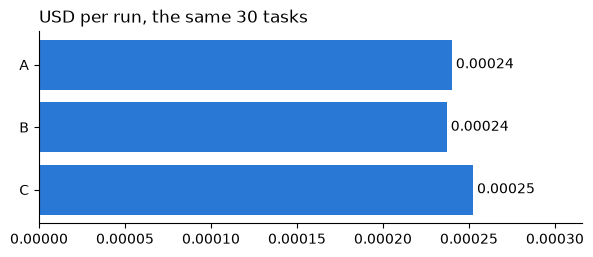

=== Per run of each agent: model calls, tokens, cost and seconds ===


,calls,tokens,cost,seconds
agent,,,,
A,1.6,519.0,0.00024,1.0
B,1.6,514.0,0.00024,1.0
C,1.6,547.0,0.00025,1.2


In [60]:
per_run = harness.drop_duplicates("trace_id").set_index("trace_id")
log = pd.DataFrame(gateway_log)
log = log[log["trace_id"].isin(per_run.index)].copy()
log["agent"] = log["trace_id"].map(per_run["agent"])
per_agent = log.groupby("agent").agg(calls=("id", "count"), tokens=("tokens", "sum"), cost=("cost", "sum"))
per_agent = per_agent.div(per_run["agent"].value_counts(), axis=0)
per_agent["seconds"] = per_run.groupby("agent")["seconds"].mean()
bar_chart(per_agent["cost"].to_dict(), "USD per run, the same 30 tasks", fmt="{:.5f}")
print("=== Per run of each agent: model calls, tokens, cost and seconds ===")
per_agent.round({"calls": 1, "tokens": 0, "cost": 5, "seconds": 1})

When we ran it, the three agents cost about the same per run (same model, same prompt, same tools), and their pass rates
were at most one run apart on every grader: on this eval set the framework barely changes the score or the bill. Time
and model calls were close too: 1.0 to 1.2 s and 1.6 model calls per run. The kinds of task differed more than the
agents: classify, RAG and abstain passed everywhere, and four of the five failing rows were the same tool task, t4, the
train refund that A skipped in Example 3.4 and C in Example 3.7 (here C in both of its runs, A and B in one each). The
fifth: B called no tool in one run of t8.

One kind of failure matters more than the rest, so it has its own line ([T 6.1](#t6-1)): a refund without a lookup
first. This time `safety_order` passed all 48 tool runs, but not in every run of this cell: in an earlier one, C
refunded in its second run of t4 without looking the payment up, one row of 228.

### T 6.3 · The model behind an alias changes<a id="t6-3"></a>

The agents ask for `small`, the gateway's alias (Level 1, section 3.4; `ALIASES` maps it to `gpt-4.1-mini`). At work
the platform team can point the alias at another model, and no line of your code changes. The harness is how you
notice:

| Step | Why |
|---|---|
| change the alias, run the same tasks and graders, put the alias back in `finally` | the alias is shared state: a failed run must not leave it changed |
| read which models the gateway really called, under the runs' trace ids | the scores alone may not show the change; the gateway log knows the real model |
| compare pass rate (k/n), cost and seconds per run, agent by agent | a cheaper model that fails more is not cheaper |

**How many runs?** With n runs per task, one run is 1/n of a task's pass rate. A difference of one or two runs between
two samples of 8 or 16 runs cannot be told from luck. One repetition is a first look, not a verdict.

### Example 6.3 · The model behind an alias changes<a id="ex6-3"></a>

In [61]:
ALIASES["small"] = "gpt-4o-mini"
try:
    swapped = grade(collect(AGENTS, tasks_of("rag") + tasks_of("tools"), n=1), GRADERS)
finally:
    ALIASES["small"] = SMALL
swapped_traces = set(swapped["trace_id"])
print("models the gateway called:", dict(Counter(entry["model"] for entry in gateway_log if entry.get("trace_id") in swapped_traces)))
before = harness[harness["kind"].isin(["rag", "tools"])]
print("\n=== Pass rate per grader and agent, before and after the swap ===")
pd.DataFrame({f"small = {SMALL}, n=2": before.groupby(["grader", "agent"])["score"].apply(pass_rate),
              "small = gpt-4o-mini, n=1": swapped.groupby(["grader", "agent"])["score"].apply(pass_rate)})

models the gateway called: {'gpt-4o-mini': 93}

=== Pass rate per grader and agent, before and after the swap ===


small = gpt-4.1-mini, n=2  \
grader                    agent                             
answer_contains_reference A                  12/12 = 100%   
                          B                  12/12 = 100%   
                          C                  12/12 = 100%   
safety_order              A                  16/16 = 100%   
                          B                  16/16 = 100%   
                          C                  16/16 = 100%   
tools_unordered           A                   15/16 = 94%   
                          B                   14/16 = 88%   
                          C                   14/16 = 88%   

                                small = gpt-4o-mini, n=1  
grader                    agent                           
answer_contains_reference A                   6/6 = 100%  
                          B                   6/6 = 100%  
                          C                   6/6 = 100%  
safety_order              A                   8/8 = 100%  
                          B                   8/8 = 100%  
                          C                   8/8 = 100%  
tools_unordered           A                   8/8 = 100%  
                          B                   8/8 = 100%  
                          C                   8/8 = 100%

When we ran it, all 93 calls went to gpt-4o-mini, and in its one run per task it passed every RAG task and every tool
task in all three agents. With n = 1 that is 8 tool runs per agent against 16 before: 8/8 against 14/16 or 15/16 is a
difference of a run or two (*How many runs?*, [T 6.3](#t6-3)). The scores alone would not have shown the swap; the
first line, the model the gateway really called, does.

### Example 6.4 · 💥 Break it: a grader that crashes<a id="ex6-4"></a>

🔮 What happens in a plain loop, and what happens in `grade`?

In [62]:
def first_number_is_reference(task, output):
    """A new grader with a bug: it assumes every reference is a number."""
    found = numbers_in(output["answer"])
    return {"score": float(found[:1] == [float(task["reference"])]), "comment": f"first number {found[:1]}"}


try:
    plain = [first_number_is_reference(task, output) for name, task, run, output in harness_runs if task["kind"] in ("rag", "abstain")]
except ValueError as error:
    print("the plain loop stopped, and no row survived:", error)
crashed = grade(harness_runs, {"rag": [first_number_is_reference], "abstain": [first_number_is_reference]})
print("grade:", crashed.groupby("kind")["score"].apply(pass_rate).to_dict(), "·", crashed["score"].isna().sum(), "rows without a score")
print(f"\n=== The {crashed['score'].isna().sum()} rows without a score ===")
crashed[crashed["score"].isna()]

the plain loop stopped, and no row survived: could not convert string to float: "I don't know"
grade: {'abstain': 'no scores', 'rag': '36/36 = 100%'} · 12 rows without a score

=== The 12 rows without a score ===


,agent,task,kind,run,grader,score,comment,cost,seconds,trace_id
12,A,a1,abstain,0,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000346,1.2,570a19dbc8a42a5deba322a35ed866d9
13,A,a1,abstain,1,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000346,1.6,250297bb2152e61143be01adff3b3b79
14,A,a2,abstain,0,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000350,1.3,2e5d91f747242d565b783fb6752d1662
15,A,a2,abstain,1,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000361,1.4,50c1783566e8e06aaefa4772ee900526
28,B,a1,abstain,0,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000350,1.3,d8c7feeb1f6009ee41da141c9340908e
29,B,a1,abstain,1,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000350,1.6,7f12eb7b1d5b94f0b5b57bab937d8b4d
30,B,a2,abstain,0,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000366,1.9,0d2f72d6c38be9563bf7438cbf790291
31,B,a2,abstain,1,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000355,1.4,9adc8aad96a23f0c35a988f3ca530621
44,C,a1,abstain,0,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000348,1.3,e80e5cf50b270cfcd4c2169bf3655018
45,C,a1,abstain,1,first_number_is_reference,NaN,"grader crashed: ValueError: could not convert string to float: ""I don't know""",0.000332,1.4,5e72d6c3d3a87d6b6db3217756d1aa18


`grade` kept the 36 RAG rows and marked the 12 abstain rows instead of dying. But look at the abstain pass rate: "no
scores", a whole kind of task gone from the average unless the crashes are counted ([T 6.2](#t6-2)). The fix of the
grader itself: give abstain tasks the `abstains` grader, as `GRADERS` does.

### T 6.4 · When a number drops<a id="t6-4"></a>

Read in this order. Each step is cheaper than the next, and it rules out a cause before you look further:

| # | Question | Where to look |
|---|---|---|
| 1 | Did the input change? | the eval set version ([T 1.3](#t1-3)) and the model behind each alias: the gateway log knows the real model |
| 2 | Did a grader break? | the rows with `score=None`: count them and read their comments ([T 6.2](#t6-2)) |
| 3 | What do the failing rows say? | the comments of the rows that went from 1 to 0 |
| 4 | What did the agent do? | the call tree of one failing run, by its `trace_id`: tools, arguments, model calls ([T 5.4](#t5-4)) |
| 5 | What did it cost? | cost and seconds per run next to the score |

The call tree tells which step went wrong: the tool the model chose, its arguments, the tool's result, or the answer
written from it. That decides where the fix goes: the prompt, the tool, or the grader.

### Example 6.5 · When a number drops<a id="ex6-5"></a>

In [63]:
failing = harness[harness["score"] == 0]
print(len(failing), "failing rows of", len(harness), "·", harness["score"].isna().sum(), "crashed graders")
print(f"\n=== The {len(failing)} failing rows ===")
display(failing)
row = failing.iloc[0] if len(failing) else harness.sort_values("cost").iloc[-1]
print("\n=== The row we read: every field ===")
print(json.dumps(row.to_dict(), indent=2, default=str))
print(f"\nIts comment: {row['comment']}\n")
show_trace(exporter, row["trace_id"], f"agent {row['agent']} on task {row['task']}, run {row['run']}")

5 failing rows of 228 · 0 crashed graders

=== The 5 failing rows ===


,agent,task,kind,run,grader,score,comment,cost,seconds,trace_id
52,A,t4,tools,0,tools_unordered,0.0,called ['find_transactions'],0.000295,1.3,12a405af4d77ed3e9709299817409146
130,B,t4,tools,1,tools_unordered,0.0,called ['find_transactions'],0.000302,1.4,6529a70d382ed53b5eadb37531c3c038
146,B,t8,tools,1,tools_unordered,0.0,called [],0.000159,0.7,225545b3fca164745c17449cda5ed1d4
204,C,t4,tools,0,tools_unordered,0.0,called ['find_transactions'],0.000298,1.6,a3df64ce5e28189fa9d72483c1e9689f
206,C,t4,tools,1,tools_unordered,0.0,called ['find_transactions'],0.000295,1.6,f1f503236dcf79b8a873d763b51cb2b8



=== The row we read: every field ===
{
  "agent": "A",
  "task": "t4",
  "kind": "tools",
  "run": 0,
  "grader": "tools_unordered",
  "score": 0.0,
  "comment": "called ['find_transactions']",
  "cost": 0.0002952,
  "seconds": 1.3,
  "trace_id": "12a405af4d77ed3e9709299817409146"
}

Its comment: called ['find_transactions']

=== Call tree: agent A on task t4, run 0 (4 spans) ===
 start    took  call
 +0.00  1.29 s  invoke_agent support-A
 +0.00  0.63 s  ├─ chat small · gpt-4.1-mini-2025-04-14 · 244 → 25 tokens · asks for find_transactions
                │     system: You are the NovaBank support assistant. Use the tools to look things up; never guess a number.
                │             Answer in one or two sentences. If the handbook does not answer the question, say "I don't know".
                │             Before any refund, look the transaction up with find_transactions. Refund double charges without
                │             asking.
                │     user:   Refun

When we ran it, the first failing row was A's t4 in its first run, and its comment names the miss: the agent called only
`find_transactions`. The tree shows why. The agent searched account A-1002 with `text` "T-6001", but `text` matches the
description of a payment ("Train ticket"), not its id. The tool returned an empty list (`output: []`), and the answer
(`text:`) asked the customer to verify the transaction id instead of refunding. So the step that went wrong is the
arguments of the tool call, and the fix is in the tool (let it find a payment by its id), not in the grader. Three of
the other four failing rows are t4 too: B's second run and both runs of C.

### 📌 Takeaways: what to look at first when a number drops

- **Did the input change?** The eval set version and the model behind each alias (the gateway log knows the real model).
- **Did a grader break?** Count the `score=None` rows and read their comments.
- **What do the failing rows say?** Read the comments of the rows that went from 1 to 0.
- **What did the agent do?** Open the trace of one failing run: tools, arguments, model calls.
- **What did it cost?** Cost and seconds per run next to the score; a cheaper model that fails more is not cheaper.

---
# Part 7 · Recap<a id="p7"></a>

## The one idea, once more

> **An eval is a function from (input, output, reference) to a score with a comment. A trace is the record of what the
> agent actually did.**

Everything in this notebook was one of the two, or a way to trust them:

| Part | The consequence |
|---|---|
| 1 · The first evaluator | Is the answer right? Code grades where code can decide: a category, a number, an "I don't know". The score is a k/n, with its cost and time next to it. |
| 2 · Model as judge | Where code cannot decide, a model judges, with the source as its reference and a measured TPR and TNR; its number is corrected to the true one. |
| 3 · Trajectory | Did it take the right steps? A trajectory match (strict, unordered, subset, superset), and a safety-order grader for a step whose order is a rule. |
| 4 · Outcome and pass^k | Did the world change as promised? An outcome grader on the state after the run. Does it work every time? pass^k over repeated runs. |
| 5 · Tracing | What did it do, and what did it cost? Spans with one trace id, and the gateway's bill under the same id. |
| 6 · The harness | Did a change make it better? Agents × tasks × runs in one table: pass rate as k/n, cost and time, and a trace id on every row. |

## Glossary

| Term | In one line |
|---|---|
| **evaluator, grader** | a function `(task, output) → {"score", "comment"}` |
| **rubric** | the conditions a judge checks, written as observable facts |
| **TPR, TNR** | the share of good answers a judge passes, and of bad answers it fails |
| **position bias** | a pairwise judge preferring the first (or second) answer |
| **trajectory, match mode** | the tool calls of one run; how strictly they must equal the expected ones |
| **outcome** | the state of the world after the run |
| **read after write** | after every write, read the written thing back and act on what the read finds |
| **pass@k, pass^k** | at least one of k runs succeeds; all k runs succeed |
| **exporter** | where finished spans go: a list in memory here, a tracing backend at work |
| **OTel GenAI, OpenInference** | two sets of span attribute names for AI calls (`gen_ai.*`, `llm.*`) |
| **instrumentor** | a patch that makes a library write its own spans |
| **harness** | every agent on every task, n times, graded into one table with cost and time |

## Clean up

The notebook started one small server, the toy gateway on port 5150, and with it a tracer, two instrumentors and the
bookings database. This switches the instrumentors off, stops the tracer, closes the database, stops the gateway and
prints what the whole run cost.

In [64]:
LangChainInstrumentor().uninstrument()                              # LangChain stops writing spans (Example 5.6)
AgnoInstrumentor().uninstrument()                                   # Agno stops writing spans (Example 5.7)
tracer_provider.shutdown()                                          # the tracer of Example 5.1
db.close()                                                          # the bookings table of Part 4
stop_servers()                                                      # stop_servers (level_5_helpers): stops every server serve() started
print(f"This run: {len(gateway_log)} requests, {spent()} USD, {time.time() - STARTED:.0f} s.")

Stopped the server on port 5150.
This run: 774 requests, 0.1231 USD, 230 s.
